<a id="practica-2-tecnicas-de-analisis"></a>

# **PRÁCTICA 2: TÉCNICAS DE ANÁLISIS**

<a id="indice"></a>

# Índice

- [PARTE 1: REGRESIÓN Y CLASIFICACIÓN](#parte-1-regresion-y-clasificacion)
- [1. Regresión: predicción del peso corporal (Weight)](#1-regresion-prediccion-del-peso-corporal-weight)
  - [1.1 Árbol de Decisión Regresor](#1-1-arbol-de-decision-regresor)
  - [1.2 Regresión Lineal (modelo de comparación)](#1-2-regresion-lineal-modelo-de-comparacion)
  - [1.3 Comparación de modelos de regresión](#1-3-comparacion-de-modelos-de-regresion)
  - [1.4 Importancia de variables – Árbol de Decisión](#1-4-importancia-de-variables-arbol-de-decision)
  - [1.5 Visualización del árbol de decisión](#1-5-visualizacion-del-arbol-de-decision)
  - [1.6 Análisis de profundidad del árbol](#1-6-analisis-de-profundidad-del-arbol)
  - [1.7 Interpretación de los resultados de regresión](#1-7-interpretacion-de-los-resultados-de-regresion)
- [2. Clasificación: predecir el nivel de obesidad (NObeyesdad)](#2-clasificacion-predecir-el-nivel-de-obesidad-nobeyesdad)
  - [2.1 Árbol de Decisión Clasificador](#2-1-arbol-de-decision-clasificador)
  - [2.2 K-Nearest Neighbours (modelo de comparación)](#2-2-k-nearest-neighbours-modelo-de-comparacion)
  - [2.3 Comparación de clasificadores](#2-3-comparacion-de-clasificadores)
  - [2.4 Matrices de confusión](#2-4-matrices-de-confusion)
  - [2.5 Curva ROC](#2-5-curva-roc)
  - [2.6 Importancia de variables – Árbol de Decisión Clasificador](#2-6-importancia-de-variables-arbol-de-decision-clasificador)
  - [2.7 Visualización del árbol de decisión clasificador](#2-7-visualizacion-del-arbol-de-decision-clasificador)
  - [2.8 Profundidad del árbol vs accuracy](#2-8-profundidad-del-arbol-vs-accuracy)
  - [2.9 Efecto del escalado](#2-9-efecto-del-escalado)
  - [2.10 Interpretación de los resultados de clasificación](#2-10-interpretacion-de-los-resultados-de-clasificacion)
- [3. Resumen](#3-resumen)
- [PARTE 2: ENSEMBLES Y CLUSTERING](#parte-2-ensembles-y-clustering)
- [1. CLUSTERING](#1-clustering)
  - [1.1 KMEANS y PCA](#1-1-kmeans-y-pca)
  - [1.2 Modelos de Mixturas Gaussianas](#1-2-modelos-de-mixturas-gaussianas)
  - [1.3 Conclusiones de los métodos de clustering.](#1-3-conclusiones-de-los-metodos-de-clustering)
- [2. ENSEMBLES](#2-ensembles)
  - [2.1 Random Forest](#2-1-random-forest)
  - [2.2 Gradient Boosting](#2-2-gradient-boosting)
  - [2.3 Voting Classifier](#2-3-voting-classifier)
  - [2.4 Comparativa final](#2-4-comparativa-final)
  - [2.6 Conclusiones de los ensembles](#2-6-conclusiones-de-los-ensembles)
- [3. Resumen](#3-resumen-2)


<a id="parte-1-regresion-y-clasificacion"></a>

## **PARTE 1: REGRESIÓN Y CLASIFICACIÓN**

Para la primera parte de la práctica realizaremos dos tareas: una de regresión y otra de clasificación. Para ello, hemos escogido el dataset **OVESITY LEVELS DATASET** (*Estimation of Obesity Levels Based on Eating Habits and Physical Condition*), que se puede encontrar en el UCI Machine Learning Repository. Este dataset cumple los requisitos especificados en el siguiente párrafo, y plantea los objetivos que se pretenden realizar, las visualizaciones a mostrar y las conclusiones extraídas.

Requisitos de las prácticas de regresión/ clasificación:

* El dataset debe de tener un mínimo de 4 dimensiones, más la variables a predecir (si se usan varios datasets que son unificados en uno solo, el número total de dimensiones debe de ser como mínimo 4) 
* En el caso del clasificador, la clasificación a realizar será del tipo multilabel (debe de tener un mínimo de 3 clases a predecir)
* Se deben usar, al menos, árboles de decisión tanto para clasificación como para regresión

El dataset escogido contiene **2.111 registros** de individuos de México, Perú y Colombia, con **16 variables** de hábitos alimenticios, actividad física y condición física, más la etiqueta de nivel de obesidad (`NObeyesdad`), que tiene 7 clases. Aproximadamente el 77% de los datos fueron generados sintéticamente mediante SMOTE a partir de 485 observaciones reales, para equilibrar las clases.

Antes de empezar con el trabajo como tal, hemos decidido realizar un pequeño análisis exploratorio de los datos para ver a qué nos enfrentaremos.

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OrdinalEncoder, StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, classification_report, confusion_matrix, mean_absolute_error, r2_score, mean_squared_error, accuracy_score, roc_auc_score, roc_curve, auc
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingRegressor, GradientBoostingClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import LinearRegression, Ridge

In [50]:
# Cargamos el dataset de obesidad.
obesity = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

# Mostramos las primeras filas para verificar que se ha cargado correctamente.
print(obesity.shape)
print(obesity.head())

(2111, 17)


   Gender   Age  Height  Weight family_history_with_overweight FAVC  FCVC  \
0  Female  21.0    1.62    64.0                            yes   no   2.0   
1  Female  21.0    1.52    56.0                            yes   no   3.0   
2    Male  23.0    1.80    77.0                            yes   no   2.0   
3    Male  27.0    1.80    87.0                             no   no   3.0   
4    Male  22.0    1.78    89.8                             no   no   2.0   

   NCP       CAEC SMOKE  CH2O  SCC  FAF  TUE        CALC  \
0  3.0  Sometimes    no   2.0   no  0.0  1.0          no   
1  3.0  Sometimes   yes   3.0  yes  3.0  0.0   Sometimes   
2  3.0  Sometimes    no   2.0   no  2.0  1.0  Frequently   
3  3.0  Sometimes    no   2.0   no  2.0  0.0  Frequently   
4  1.0  Sometimes    no   2.0   no  0.0  0.0   Sometimes   

                  MTRANS           NObeyesdad  
0  Public_Transportation        Normal_Weight  
1  Public_Transportation        Normal_Weight  
2  Public_Transportation        

Las columnas de las que disponemos son:

**Datos demográficos y antropométricos**
1. **Gender**: género del individuo (`Female`, `Male`). Categórica.
2. **Age**: edad en años. Numérica.
3. **Height**: altura en metros. Numérica.
4. **Weight**: peso en kilogramos. Numérica. *(Será nuestra variable objetivo en regresión.)*

**Antecedentes e información de hábitos alimenticios**

5. **family_history_with_overweight**: si algún familiar ha tenido sobrepeso (`yes`/`no`). Binaria.
6. **FAVC** (*Frequent consumption of high caloric food*): si consume comida alta en calorías de forma frecuente (`yes`/`no`).
7. **FCVC** (*Frequency of Consumption of Vegetables*): frecuencia de consumo de verduras. Escala 1–3.
8. **NCP** (*Number of main meals*): número de comidas principales al día. Escala 1–4.
9. **CAEC** (*Consumption of food between meals*): frecuencia de picoteo entre horas (`no`, `Sometimes`, `Frequently`, `Always`). Ordinal.
10. **CH2O** (*Daily water consumption*): litros de agua al día. Escala 1–3.
11. **CALC** (*Consumption of alcohol*): frecuencia de consumo de alcohol (`no`, `Sometimes`, `Frequently`, `Always`). Ordinal.

**Estilo de vida y actividad**

12. **SMOKE**: si fuma (`yes`/`no`). Binaria.
13. **SCC** (*Calories consumption monitoring*): si monitoriza las calorías que consume (`yes`/`no`). Binaria.
14. **FAF** (*Physical activity frequency*): frecuencia de actividad física semanal. Escala 0–3.
15. **TUE** (*Time using technology devices*): horas diarias usando dispositivos tecnológicos. Escala 0–2.
16. **MTRANS** (*Transportation used*): medio de transporte habitual (`Automobile`, `Motorbike`, `Bike`, `Public_Transportation`, `Walking`). Categórica.

17. **NObeyesdad**: nivel de obesidad. Tiene 7 clases y será nuestra variable objetivo de clasificación:
    - `Insufficient_Weight`
    - `Normal_Weight`
    - `Overweight_Level_I`
    - `Overweight_Level_II`
    - `Obesity_Type_I`
    - `Obesity_Type_II`
    - `Obesity_Type_III`


In [51]:
# Veamos cuántos individuos hay de cada género.
print(obesity['Gender'].value_counts())

Gender
Male      1068
Female    1043
Name: count, dtype: int64


Están bastante bien equilibradas las clases, lo que hace que sea menos probable que nuestro trabajo caiga en sesgos o descalibres.

In [52]:
# Vamos a cambiar los nombres de las clases para que sean mas legibles.
obesity['NObeyesdad'] = obesity['NObeyesdad'].replace({
    'Insufficient_Weight': 'Insuficiente',
    'Normal_Weight': 'Normal',
    'Overweight_Level_I': 'Sobrepeso I',
    'Overweight_Level_II': 'Sobrepeso II',
    'Obesity_Type_I': 'Obesidad  I',
    'Obesity_Type_II': 'Obesidad II',
    'Obesity_Type_III': 'Obesidad III'
})

# Veamos cuántos individuos hay de cada nivel de obesidad.
print(obesity['NObeyesdad'].value_counts())


NObeyesdad
Obesidad  I     351
Obesidad III    324
Obesidad II     297
Sobrepeso I     290
Sobrepeso II    290
Normal          287
Insuficiente    272
Name: count, dtype: int64


De nuevo, también están relativamente bien equilibradas las clases, lo cual nos facilita el trabajo.

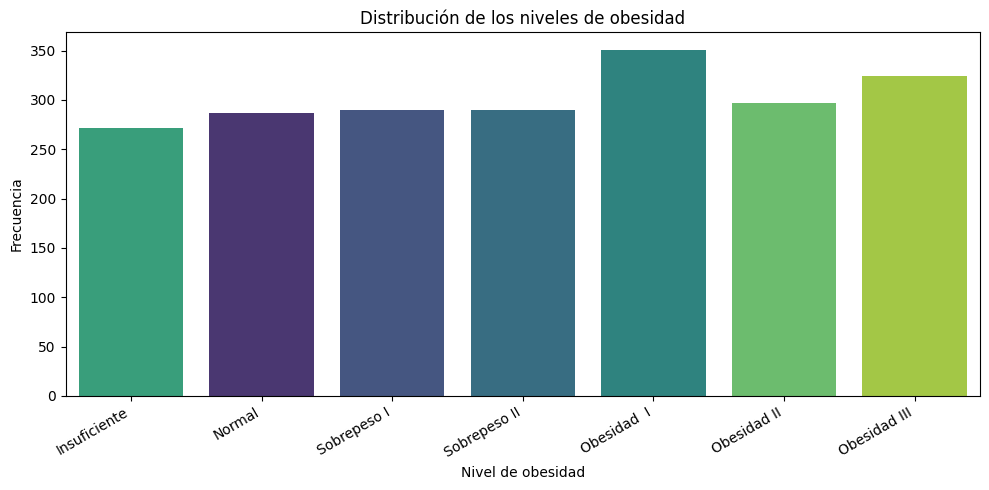

In [98]:
# Visualizamos la distribución de las clases de obesidad.
order = ['Insuficiente', 'Normal', 'Sobrepeso I', 'Sobrepeso II', 'Obesidad  I', 'Obesidad II', 'Obesidad III']

plt.figure(figsize=(10,5))
sns.countplot(data=obesity, x='NObeyesdad', order=order, palette='viridis', hue='NObeyesdad')
plt.title('Distribución de los niveles de obesidad')
plt.xlabel('Nivel de obesidad')
plt.ylabel('Frecuencia')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

Las clases están **bastante equilibradas** (entre ~270 y ~350 muestras cada una), lo cual es consecuencia del proceso de balanceo mediante SMOTE aplicado por los autores del dataset. Esto es una gran ventaja para nuestros modelos de clasificación y de ensembles, ya que no necesitaremos aplicar técnicas de resampling adicionales.

El género también está repartido de forma razonablemente equilibrada (~50/50).

Vamos a seguir con un pequeño análisis exploratorio y de correlación entre las variables clave.

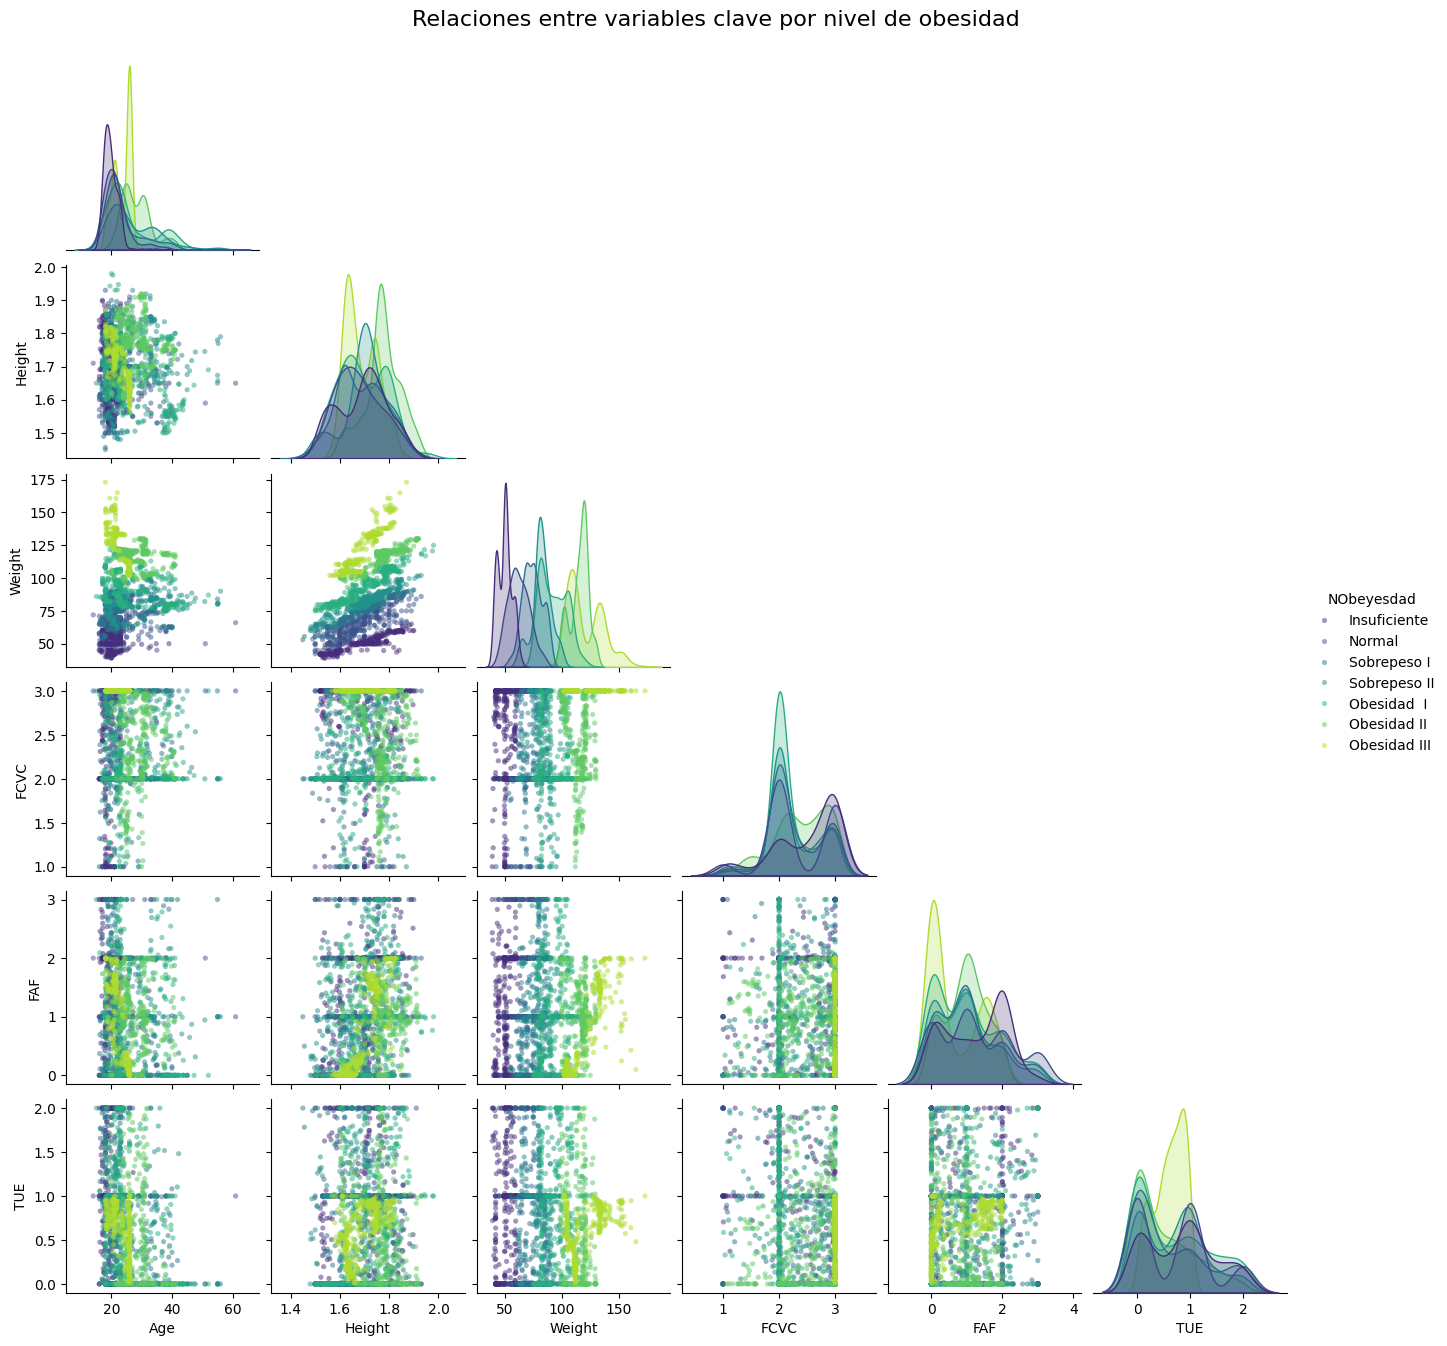

In [54]:
# Seleccionamos las variables numéricas clave para el análisis visual.
vars_key = [
    "Age",     # edad: buen discriminador entre clases jóvenes / mayores
    "Height",  # altura: complementa peso para entender BMI
    "Weight",  # variable objetivo de regresión, principal correlato con la etiqueta
    "FCVC",    # consumo de verduras
    "FAF",     # frecuencia de actividad física
    "TUE",     # tiempo frente a pantallas
]

sns.pairplot(
    obesity.dropna(),
    vars=vars_key,
    hue="NObeyesdad",
    hue_order=order,
    diag_kind="kde",
    kind="scatter",
    height=2.2,
    plot_kws={"alpha": 0.5, "s": 14, "edgecolor": "none"},
    corner=True,
    palette="viridis",
)
plt.suptitle("Relaciones entre variables clave por nivel de obesidad", y=1.02, fontsize=16)
plt.show()

Como podemos ver en el pairplot:

* **`Weight`** es, con diferencia, la variable que mejor separa las clases: las KDE de la diagonal muestran picos claramente ordenados de `Insuficiente` (≈45 kg) hasta `Obesidad III` (≈115 kg). Esto es esperable ya que la etiqueta se construye a partir del IMC, que depende directamente del peso.
* **`Height`** tiene distribuciones muy solapadas entre clases; por sí sola aporta poca información, pero combinada con `Weight` define el IMC.
* **`Age`** muestra que las clases de obesidad severa (Tipos II y III) se concentran en edades algo mayores, mientras que `Insuficiente` está sesgada hacia individuos más jóvenes.
* **`FAF` (actividad física)** tiende a ser mayor en clases de peso normal o insuficiente y menor en obesidad tipo III, aunque con bastante solapamiento.
* **`FCVC` (consumo de verduras)** y **`TUE` (tiempo de pantalla)** son mucho más ruidosas y no separan bien las clases por sí solas.

El par **`Weight` vs `Height`** dibuja claramente las curvas de nivel del IMC, con las clases apareciendo como bandas diagonales. Es el par más discriminativo. Esto nos indica que un modelo simple basado en estas dos variables ya conseguirá una tasa de acierto alta, pero también que gran parte del reto de la práctica está en **predecir el nivel de obesidad sin usar `Weight` y `Height`** (es decir, solo a partir de hábitos), que es donde aparecen patrones realmente interesantes.


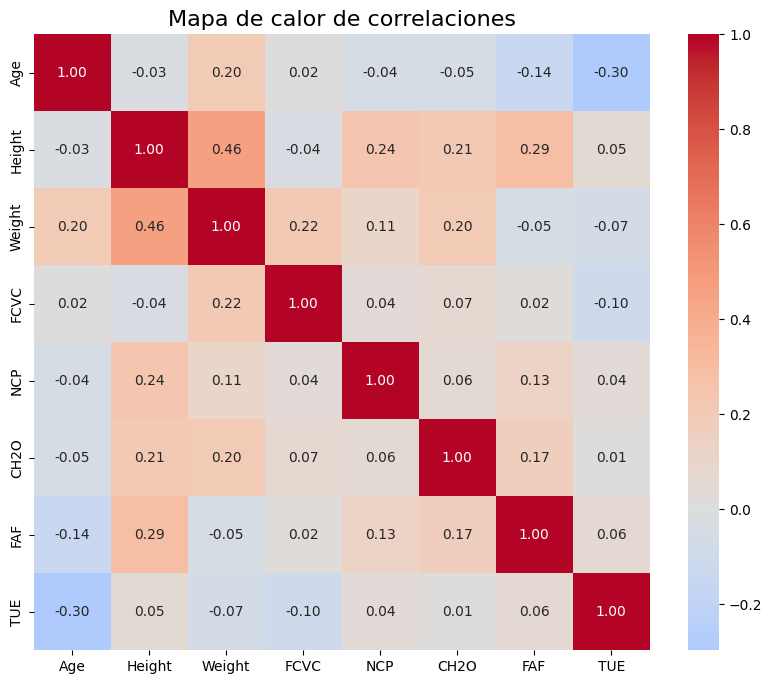

In [55]:
# Mapa de calor de correlaciones entre variables numéricas.
num_cols = obesity.select_dtypes(include=[np.number]).columns

plt.figure(figsize=(10,8))
sns.heatmap(obesity[num_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True)
plt.title("Mapa de calor de correlaciones", fontsize=16)
plt.show()

En general, no hay ninguna correlación alta como tal, porque ninguna supera el 0.5.
Si tuvierámos que mencionar algunas entre las variables numéricas diríamos:

* **`Weight` vs `Height`** (≈0.46): correlación positiva moderada, coherente (las personas más altas tienden a pesar más), y es la base sobre la que se construye el IMC.
* **`Age` vs `Weight`** (≈0.20): ligera correlación positiva; el peso tiende a aumentar con la edad en este dataset.
* **`TUE` (tiempo de pantallas) vs `Age`** (≈-0.30): los individuos jóvenes pasan más tiempo delante de dispositivos tecnológicos.
* **`FAF` vs `Height`** (≈0.29): ligera correlación positiva, lo cual tampoco nos dice mucho porque el que a mayor altura mayor actividad física no tiene mucho sentido real.
* Las variables de hábitos (`FCVC`, `NCP`, `CH2O`, `FAF`, `TUE`) tienen **correlaciones lineales bajas entre sí**, lo que indica que capturan dimensiones relativamente independientes del estilo de vida. Esto es una buena noticia para los modelos no lineales (árboles, ensembles), que podrán explotar interacciones.

Este heatmap solo considera las variables numéricas. Variables categóricas importantes como `family_history_with_overweight`, `CAEC`, `CALC` o `MTRANS` requerirán un tratamiento aparte (codificación ordinal o one-hot) antes de entrar en los modelos, y analizaremos su relación con la etiqueta mediante tablas de contingencia o gráficos de barras apiladas más adelante.


PREPROCESAMIENTO DE LAS VARIABLES:

In [56]:
obesity = pd.DataFrame(obesity)

# Queremos convertir a escalas las variables CAE y CALC, que son ordinales.
ordinal_cols = ["CAEC", "CALC"]
for col in ordinal_cols:
    obesity[col] = obesity[col].map({
        "no": 0,
        "Sometimes": 1,
        "Frequently": 2,
        "Always": 3
    })

# Convertimos sexo a 0 = Male y 1 = Female
obesity['Gender'] = obesity['Gender'].map({'Male': 0, 'Female': 1})

# Hacemos la misma transformación para las variables binarias.
binary_cols = ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]
for col in binary_cols:
    obesity[col] = obesity[col].map({"no": 0, "yes": 1})

# One-hot para la única categórica nominal (sin orden): MTRANS
obesity = pd.get_dummies(obesity, columns=["MTRANS"], prefix="MTRANS", drop_first=False, dtype=int)

print(obesity.head())

   Gender   Age  Height  Weight  family_history_with_overweight  FAVC  FCVC  \
0       1  21.0    1.62    64.0                               1     0   2.0   
1       1  21.0    1.52    56.0                               1     0   3.0   
2       0  23.0    1.80    77.0                               1     0   2.0   
3       0  27.0    1.80    87.0                               0     0   3.0   
4       0  22.0    1.78    89.8                               0     0   2.0   

   NCP  CAEC  SMOKE  ...  SCC  FAF  TUE  CALC    NObeyesdad MTRANS_Automobile  \
0  3.0     1      0  ...    0  0.0  1.0     0        Normal                 0   
1  3.0     1      1  ...    1  3.0  0.0     1        Normal                 0   
2  3.0     1      0  ...    0  2.0  1.0     2        Normal                 0   
3  3.0     1      0  ...    0  2.0  0.0     2   Sobrepeso I                 0   
4  1.0     1      0  ...    0  0.0  0.0     1  Sobrepeso II                 0   

   MTRANS_Bike  MTRANS_Motorbike  MTRA

Vamos a hacer dos modelos supervisados sobre el dataset de obesidad que ya hemos cargado y preprocesado:

1. **Regresión**: predecir el **peso** (`Weight`) a partir de los hábitos y características del individuo.
2. **Clasificación**: predecir el **nivel de obesidad** (`NObeyesdad`), que tiene 7 clases distintas.

En ambos casos usaremos como mínimo un **árbol de decisión** (CART, que es el que implementa scikit-learn). Lo compararemos con otro modelo para ver si mejora o empeora.

<a id="1-regresion-prediccion-del-peso-corporal-weight"></a>

## 1. Regresión: predicción del peso corporal (`Weight`)

El objetivo de este apartado es estimar el peso en kg de un individuo a partir de sus características y hábitos, sin usar directamente la etiqueta de obesidad.

El peso es la variable que define el IMC (junto con la altura) y, por lo tanto, es la clase de obesidad. Si podemos estimar bien el peso solo con los hábitos, tenemos un modelo útil para la prevención.

### Separamos features y target

In [57]:
# usamos todos menos el peso (objetivo) y la etiqueta de obesidad

features_reg = [c for c in obesity.columns if c not in ['Weight', 'NObeyesdad']]

X = obesity[features_reg]
y = obesity['Weight']

# Split 80/20 con random_state fijo para reproducibilidad
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Entrenamiento: {X_train.shape}")
print(f"Test: {X_test.shape}")

Entrenamiento: (1688, 19)
Test: (423, 19)


<a id="1-1-arbol-de-decision-regresor"></a>

### 1.1 Árbol de Decisión Regresor

En regresión el árbol usa el **error cuadrático medio (MSE)** como criterio para elegir los splits. En cada hoja predice la media de los valores que contiene.



In [58]:
# entrenamos el arbol con profundidad maxima de 5 y un minimo de 10 muestras por hoja para evitar overfitting
arbol_reg = DecisionTreeRegressor(max_depth=5, min_samples_leaf=10, random_state=42)
arbol_reg.fit(X_train, y_train)

y_pred_arbol = arbol_reg.predict(X_test)

# calculamos las metricas
rmse_arbol = np.sqrt(mean_squared_error(y_test, y_pred_arbol))
mae_arbol = mean_absolute_error(y_test, y_pred_arbol)
r2_arbol = r2_score(y_test, y_pred_arbol)

print("Árbol de Decisión")
print(f"    RMSE: {rmse_arbol:.2f} kg")
print(f"    MAE:  {mae_arbol:.2f} kg")
print(f"    R²:   {r2_arbol:.3f}")

Árbol de Decisión
    RMSE: 14.52 kg
    MAE:  10.36 kg
    R²:   0.701


<a id="1-2-regresion-lineal-modelo-de-comparacion"></a>

### 1.2 Regresión Lineal (modelo de comparación)

La regresión lineal nos permite ver que si la relación entre los hábitos y el peso no es lineal, el árbol debería de hacerlo mejor.

También vamos a probar usando Ridge, que es la versión de la regresión lineal que penaliza los coeficientes grandes para evitar overfitting y multicolinealidad.

In [59]:
# regresión lineal

reg_lineal = LinearRegression()
reg_lineal.fit(X_train, y_train)
y_pred_lr = reg_lineal.predict(X_test)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr  = mean_absolute_error(y_test, y_pred_lr)
r2_lr   = r2_score(y_test, y_pred_lr)

print("Regresión Lineal")
print(f"    RMSE : {rmse_lr:.2f} kg")
print(f"    MAE  : {mae_lr:.2f} kg")
print(f"    R²   : {r2_lr:.3f}")

Regresión Lineal
    RMSE : 17.79 kg
    MAE  : 14.28 kg
    R²   : 0.551


In [60]:
# Ridge (lo mismo pero con regularizacion l2)

ridge = Ridge(alpha=1.0) # alfa= controla la penalizacion
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_test)

rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Regresión Ridge")
print(f"    RMSE: {rmse_ridge:.2f} kg")
print(f"    MAE:  {mae_ridge:.2f} kg")
print(f"    R²:   {r2_ridge:.3f}")

Regresión Ridge
    RMSE: 17.75 kg
    MAE:  14.19 kg
    R²:   0.553


<a id="1-3-comparacion-de-modelos-de-regresion"></a>

### 1.3 Comparación de modelos de regresión

In [61]:
resultados = pd.DataFrame({
    'Modelo': ['Árbol de Decisión', 'Regresión Lineal', 'Ridge'],
    'RMSE': [rmse_arbol, rmse_lr, rmse_ridge],
    'MAE': [mae_arbol, mae_lr, mae_ridge],
    'R2': [r2_arbol, r2_lr, r2_ridge]
})
print(resultados.to_string(index=False))

           Modelo      RMSE       MAE       R2
Árbol de Decisión 14.524713 10.356705 0.700803
 Regresión Lineal 17.786286 14.282497 0.551344
            Ridge 17.754310 14.193838 0.552956


Vemos que el menor RMSE y MAE lo conseguimos con el árbol de decisión, igual que el mayor $R^2$. Es decir, con el árbol de decisión, el error medio de kg es RMSE=14.52kg y MAE=10.36kg, y el modelo explica el 70% de la varianza del peso, mientras que los otros dos tienen aproximadamente un RMSE de 17.7kg y un MAE de 14.2kg, y apenas llegan a explicar el 55% de la varianza del peso. Por lo tanto el árbol de decisión es el más eficaz para predecir. 

A continuación creamos un gráfico para comparar el RMSE y $R^2$ de cada modelo visualmente.

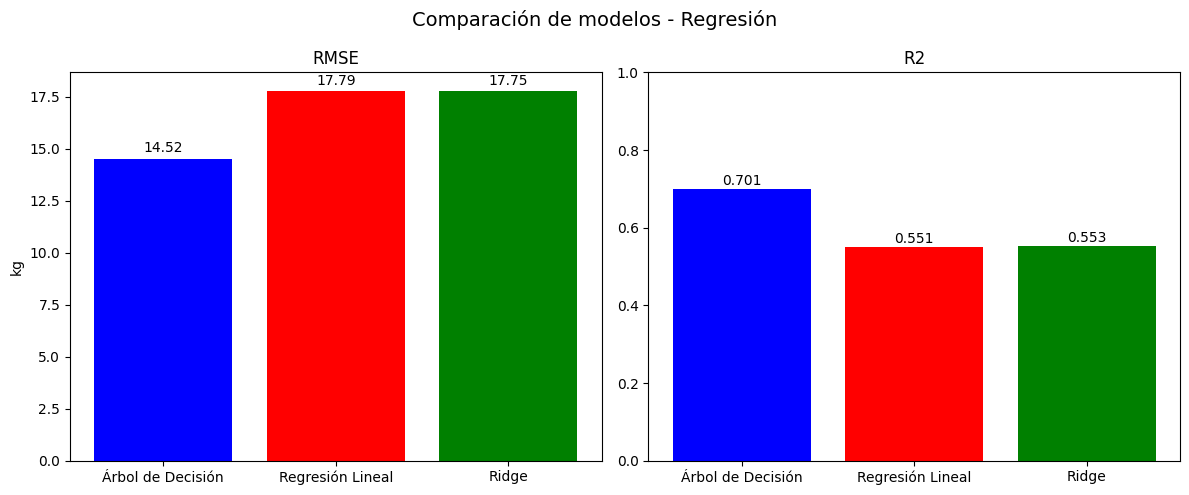

In [62]:
# graficamos RMSE y R2 para comparar visualmente

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

modelos = resultados['Modelo']
colores = ['blue', 'red', 'green']

axes[0].bar(modelos, resultados['RMSE'], color=colores)
axes[0].set_title('RMSE')
axes[0].set_ylabel('kg')
for i, v in enumerate(resultados['RMSE']):
    axes[0].text(i, v + 0.3, f'{v:.2f}', ha='center')

axes[1].bar(modelos, resultados['R2'], color=colores)
axes[1].set_title('R2')
axes[1].set_ylim(0, 1)
for i, v in enumerate(resultados['R2']):
    axes[1].text(i, v + 0.01, f'{v:.3f}', ha='center')

plt.suptitle('Comparación de modelos - Regresión', fontsize=14)
plt.tight_layout()
plt.show()

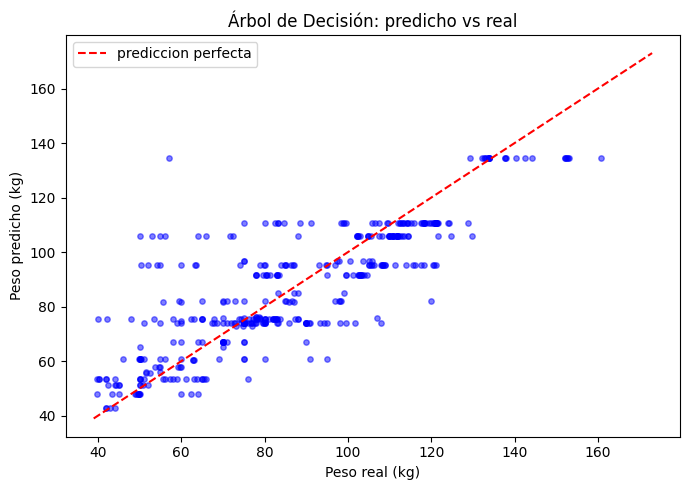

In [63]:
# Grafico de predicho vs real para el arbol de decision
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred_arbol, alpha=0.5, s=15, color='blue')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='prediccion perfecta')
plt.xlabel('Peso real (kg)')
plt.ylabel('Peso predicho (kg)')
plt.title('Árbol de Decisión: predicho vs real')
plt.legend()
plt.tight_layout()
plt.show()

Observamos una clara disposición de los puntos en franjas horizontales. Esto nos indica que el modelo está agrupando las predicciones en valores constantes (nodos hoja), lo que nos demuestra que el Árbol de Decisión está simplificando la realidad y no es capaz de capturar la naturaleza continua del peso de forma fluida.

Por otro lado, vemos que el modelo tiene dificultades para predecir pesos elevados (superiores a 130 kg). En este rango, casi todos los puntos se sitúan por debajo de la línea de predicción perfecta, lo que nos confirma un sesgo sistemático hacia la baja en casos de obesidad severa.

El modelo nos muestra su mejor desempeño en el intervalo de 40 kg a 80 kg, donde los puntos se agrupan con mayor densidad en torno a la diagonal. Esto nos sugiere que el modelo es más preciso para individuos con pesos promedio, pero pierde fiabilidad en los extremos de la distribución.

Finalmente, la incapacidad de los puntos para seguir la diagonal de forma lineal sugiere que un único Árbol de Decisión no es suficiente para este problema. El modelo actual tiende al infraajuste (underfitting) en los valores altos y a una excesiva rigidez en sus decisiones.

<a id="1-4-importancia-de-variables-arbol-de-decision"></a>

### 1.4 Importancia de variables – Árbol de Decisión

Los árboles no tienen coeficientes como la regresión lineal, pero sí tienen `feature_importances_`, que indica cuánto contribuye cada variable a reducir el MSE en las divisiones del árbol.

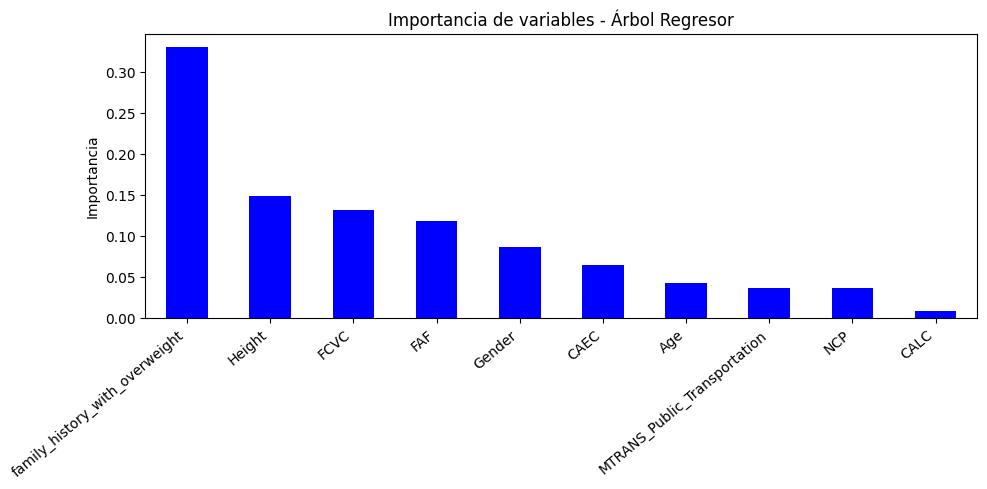

Top 5 variables más importantes:
family_history_with_overweight    0.329819
Height                            0.148054
FCVC                              0.131727
FAF                               0.118265
Gender                            0.086385
dtype: float64


In [64]:
importancias = pd.Series(arbol_reg.feature_importances_, index=features_reg)
importancias = importancias.sort_values(ascending=False)

plt.figure(figsize=(10, 5))
importancias.head(10).plot(kind='bar', color='blue')
plt.title('Importancia de variables - Árbol Regresor')
plt.ylabel('Importancia')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

print("Top 5 variables más importantes:")
print(importancias.head(5))

Vemos que la variable más importante con diferencia a la hora de tener sobrepeso o no es el historial familiar de sobrepeso, es decir, los factores genéticos o del entorno familiar son los predictores más críticos del peso. Seguido de la altura, la frecuencia de consumo de verduras y la frecuencia de actividad física semanal, qu ejuntas aportan una capacidad predictiva significativa.

Por el contrario, factores como la edad, el medio de transporte o el consumo de alcohol muestran una muy pequeña influencia en el resultado final del modelo.

<a id="1-5-visualizacion-del-arbol-de-decision"></a>

### 1.5 Visualización del árbol de decisión

Como los árboles son interpretables podemos ver qué reglas sigue para hacer la predicción. Vamos a mostrar los primeros 3 niveles.

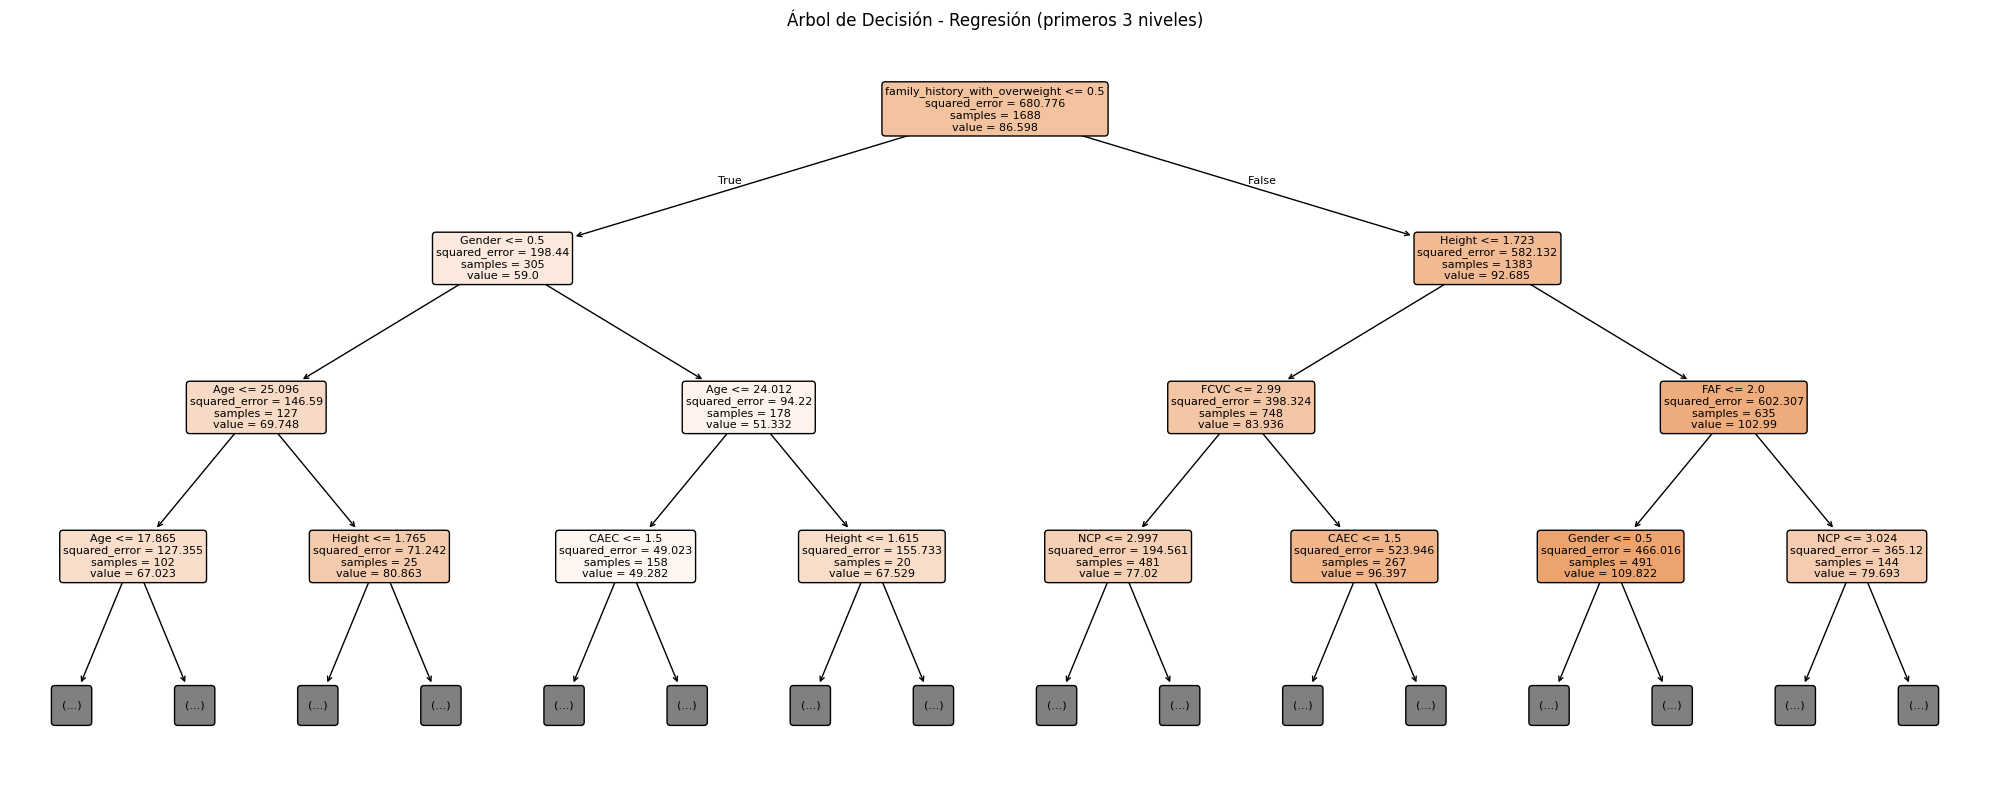

In [65]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 8))
plot_tree(arbol_reg,
          feature_names=features_reg,
          filled=True,
          rounded=True,
          max_depth=3,
          fontsize=8)
plt.title('Árbol de Decisión - Regresión (primeros 3 niveles)')
plt.tight_layout()
plt.show()

El diagrama del árbol nos confirma que la raíz de la toma de decisiones es el historial familiar de sobrepeso (`family_history_with_overweight`), siendo así la variable más importante. La primera división separa el dataset en un grupo con un peso promedio de 59kg (sin antecedentes) frente a otro significativamente mayor de 92.68 kg (con antecedentes). Esto marca la trayectoria de todas las predicciones posteriores, demostrando que el historial familiar es el principal condicionante del modelo.

En el segundo nivel, observamos que el modelo predice utilizando la altura (`Height`) y la edad (`Age`) para los perfiles de menos peso, mientras que para los perfiles de más peso prioriza hábitos de consumo como comer vegetales (`FCVC`) y la actividad física (`FAF`).

<a id="1-6-analisis-de-profundidad-del-arbol"></a>

### 1.6 Análisis de profundidad del árbol

Si no controlamos la profundidad del árbol, éste puede hacer overfitting. Por lo tanto, vamos a ver cómo cambia $R^2$ en train y en test para distintos valores de `max_depth` para justificar la elección de `max_depth=5`.

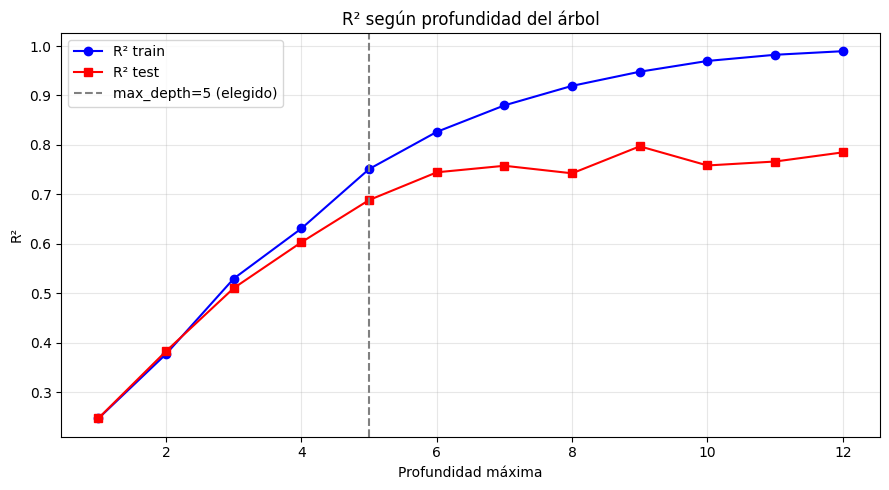

In [66]:
depths = list(range(1, 13))
r2_train_list = []
r2_test_list = []

for d in depths:
    m = DecisionTreeRegressor(max_depth=d, random_state=42)
    m.fit(X_train, y_train)
    r2_train_list.append(r2_score(y_train, m.predict(X_train)))
    r2_test_list.append(r2_score(y_test, m.predict(X_test)))

plt.figure(figsize=(9, 5))
plt.plot(depths, r2_train_list, 'o-', label='R² train', color='blue')
plt.plot(depths, r2_test_list, 's-', label='R² test', color='red')
plt.axvline(x=5, color='gray', linestyle='--', label='max_depth=5 (elegido)')
plt.xlabel('Profundidad máxima')
plt.ylabel('R²')
plt.title('R² según profundidad del árbol')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Vemos que la elección de una profundidad máxima de 5 es una decisión estratégica para evitar el sobreajuste (overfitting). Hasta este punto, las curvas de entrenamiento y test crecen de forma casi paralela. 

A partir de una profundidad de 6, la métrica de entrenamiento continúa ascendiendo hacia el valor de 1.0, mientras que la métrica de test se estanca y comienza a oscilar. Esto nos dice que un árbol más profundo empezaría a "memorizar" el ruido del conjunto de entrenamiento en lugar de aprender la lógica subyacente de los datos.

Por lo tanto, la profundidad 5 nos ofrece un modelo más explicable. Al mantener una profundidad controlada, garantizamos que el modelo sea menos sensible a pequeñas variaciones en los datos de entrada y que las reglas de decisión extraídas sean robustas y fiables para su aplicación práctica.

<a id="1-7-interpretacion-de-los-resultados-de-regresion"></a>

### 1.7 Interpretación de los resultados de regresión

El árbol de decisión obtiene un $R^2$ de 0.70 y un RMSE de 14.5kg, mientras que la regresión lineal y Ridge consiguen aproximadamente un $R^2$ de 0.55 y un RMSE de 17.8kg. Esto nos confirma que cuando la relación entre las variables no es lineal, el árbol captura mejor esas interacciones.

La curva de validación nos muestra cómo a partir de profundidad 7-8 el modelo empieza a sobreajustar: el $R^2$ en train sigue subiendo pero en test se estanca. Elegimos `max_depth=5`.

La variable más importante es `family_history_with_overweight`, seguida de `Height` (la altura define el rango plausible de peso) y algunas variables de hábitos como `FCVC` y `FAF`.

**Limitación:** un $R^2$ de 0.70 con 14kg de error es bueno pero podría mejorar, lo que tiene sentido porque el peso depende también de factores no recogidos en el dataset (metabolismo, historial médico, etc.).

<a id="2-clasificacion-predecir-el-nivel-de-obesidad-nobeyesdad"></a>

## 2. Clasificación: predecir el nivel de obesidad (`NObeyesdad`)

En este apartado predecimos la clase de obesidad de un individuo entre 7 categorías diferentes, incluyendo el peso como variable de entrada. Es una clasificación multiclase (≥ 3 clases) en la que usamos:

- **Árbol de Decisión Clasificador**
- **K-Nearest Neighbours (KNN)** como modelo de comparación.

### Split de los datos

In [67]:
# Usamos todas las variables
features_clf = [c for c in obesity.columns if c != 'NObeyesdad']

X_clf = obesity[features_clf]
y_clf = obesity['NObeyesdad']

# Usamos stratify para que todas las clases tengan representacion en train y test
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

print(f"Train: {X_train_c.shape}, Test: {X_test_c.shape}")
print()
print("Distribución en test:")
print(y_test_c.value_counts())

Train: (1688, 20), Test: (423, 20)

Distribución en test:
NObeyesdad
Obesidad  I     70
Obesidad III    65
Obesidad II     60
Normal          58
Sobrepeso II    58
Sobrepeso I     58
Insuficiente    54
Name: count, dtype: int64


Hay un equilibrio notable entre todas las categorias de peso en el test. Con 423 registros en el cojunto de test, cada categoría tiene entre 54 y 40 ejemplos.

<a id="2-1-arbol-de-decision-clasificador"></a>

### 2.1 Árbol de Decisión Clasificador

El árbol CART usa la impureza de Gini para elegir los splits:

$$Gini(n) = 1 - \sum_{i=1}^{Z} p_i^2$$

Donde $p_i$ es la proporción de muestras de la clase $i$ en el nodo. Cuanto más bajo el Gini, más "puro" es el nodo (las muestras son más de la misma clase).

Ponemos `criterion='gini'` que es el que implementa CART en scikit-learn.

In [68]:
# Arbol con Gini (CART)
arbol_clf = DecisionTreeClassifier(criterion='gini', max_depth=6, min_samples_leaf=5, random_state=42)
arbol_clf.fit(X_train_c, y_train_c)

y_pred_arbol_c = arbol_clf.predict(X_test_c)

acc_arbol = accuracy_score(y_test_c, y_pred_arbol_c)
print(f"Accuracy del Árbol de Decisión: {acc_arbol:.3f}\n")
print(classification_report(y_test_c, y_pred_arbol_c, target_names=order))

Accuracy del Árbol de Decisión: 0.861

              precision    recall  f1-score   support

Insuficiente       0.98      0.87      0.92        54
      Normal       0.75      0.78      0.76        58
 Sobrepeso I       0.78      0.90      0.83        70
Sobrepeso II       0.97      0.95      0.96        60
 Obesidad  I       1.00      0.98      0.99        65
 Obesidad II       0.73      0.88      0.80        58
Obesidad III       0.90      0.64      0.75        58

    accuracy                           0.86       423
   macro avg       0.87      0.86      0.86       423
weighted avg       0.87      0.86      0.86       423



El modelo del Árbol de Decisión tiene un Accuracy del 86.1%, lo que indica una alta capacidad para categorizar correctamente los niveles de obesidad.

Destaca sobretodo el *f1-score* de Obesidad I con un valor de 0.99 y de Sobrepeso II con un valor de 0.96. Además, la precisión de Obesidad I es de 1, lo que significa que el modelo no ha hecho ningún falso positivo en esta categoría.

Por otro lado, vemos que el *recall* de Obesidad III es de 0.64, lo que indica que el modelo identifica solo el 64% de los individuos que pertenecen a esta categoría, clasificando los demás erroneamente en otros niveles. Además, las categorias Normal y Obesidad II tienen los valores de *f1-score* bajos (0.76 y 0.80) debido a una menor precisión (0.75 y 0.73), lo que nos sugiere que hay fronteras confusas entre estas categorías y sus adyacentes.

Finalmente, tanto el *macro avg* como el *weighted avg* se mantienen en 0.86, lo que nos confirma que el modelo es robusto y mantiene un rendimiento equilibrado a través de todo el dataset.

<a id="2-2-k-nearest-neighbours-modelo-de-comparacion"></a>

### 2.2 K-Nearest Neighbours (modelo de comparación)

KNN necesita datos escalados porque mide distancias euclídeas. Aplicamos `StandardScaler`.

In [69]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_c)
X_test_scaled = scaler.transform(X_test_c)

knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(X_train_scaled, y_train_c)

y_pred_knn = knn.predict(X_test_scaled)

acc_knn = accuracy_score(y_test_c, y_pred_knn)

print(f"Accuracy del KNN (K=7): {acc_knn:.3f}")
print()
print(classification_report(y_test_c, y_pred_knn, target_names=order))

Accuracy del KNN (K=7): 0.797

              precision    recall  f1-score   support

Insuficiente       0.76      0.96      0.85        54
      Normal       0.71      0.55      0.62        58
 Sobrepeso I       0.68      0.89      0.77        70
Sobrepeso II       0.87      0.90      0.89        60
 Obesidad  I       0.96      1.00      0.98        65
 Obesidad II       0.76      0.60      0.67        58
Obesidad III       0.86      0.64      0.73        58

    accuracy                           0.80       423
   macro avg       0.80      0.79      0.79       423
weighted avg       0.80      0.80      0.79       423



El algoritmo KNN tiene un Accuracy del 79.7%, lo que indica un rendimiento inferior al del Árbol de Decisión. 

Igual que en el modelo anterior, Obesidad I es la clase más robusta con un *recall* de 1, lo que nos dice que el algritmo ha identificado el 100% de los individuos con Obesidad de nivel I del conjunto de test. Además tiene un *f1-score* de 0.98, lo que indica que es la clase más distinguible para el modelo.

Por otro lado, la clase Normal tiene el peor desempeño con un *recall* de 0.55 y un *f1-score* de 0.62. Lo que nos indica que el 38% de las personas con peso normal están siendo mal clasificadas en categorias adyacentes. 

Por último, observamos una gran disparidad en la capacidad de detección del modelo: de los valores de *recall* más altos (depues de Obesidad I) son de Insuficiente (0.96) y Sobrepeso (0.89), mienras qu elos valores más bajos son de Obesidad II (0.6) y Obesidad III (0.64).

A continuación comparamos el accuracy de los dos modelos visualmente mediante una gráfica.

<a id="2-3-comparacion-de-clasificadores"></a>

### 2.3 Comparación de clasificadores

Accuracy Árbol de Decisión : 0.861
Accuracy KNN (k=7)         : 0.797


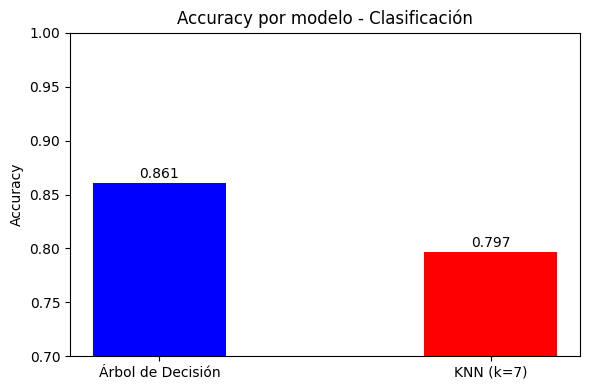

In [70]:
print(f"Accuracy Árbol de Decisión : {acc_arbol:.3f}")
print(f"Accuracy KNN (k=7)         : {acc_knn:.3f}")

plt.figure(figsize=(6, 4))
plt.bar(['Árbol de Decisión', 'KNN (k=7)'], [acc_arbol, acc_knn],
        color=['blue', 'red'], width=0.4)
for i, v in enumerate([acc_arbol, acc_knn]):
    plt.text(i, v + 0.005, f'{v:.3f}', ha='center')
plt.ylim(0.7, 1.0)
plt.title('Accuracy por modelo - Clasificación')
plt.ylabel('Accuracy')
plt.tight_layout()
plt.show()

<a id="2-4-matrices-de-confusion"></a>

### 2.4 Matrices de confusión

Con la matriz de confusión vemos dónde falla cada modelo.

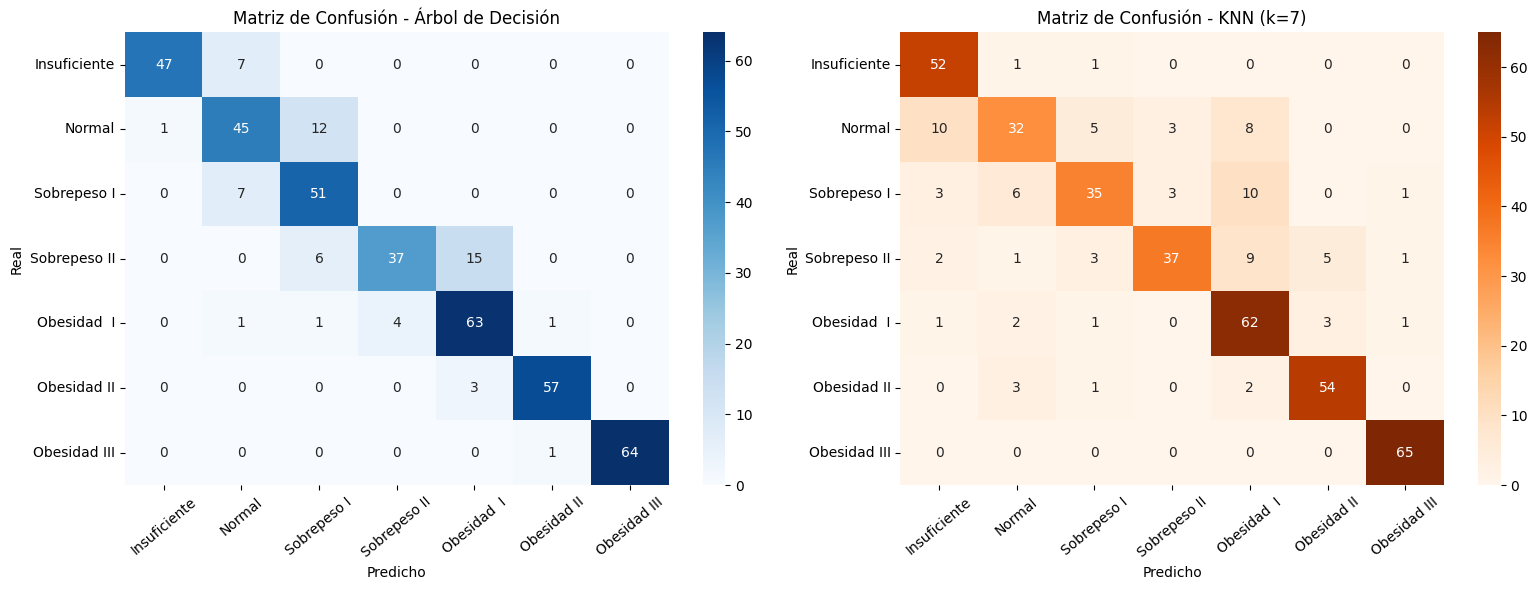

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, nombre, y_pred, cmap in zip(
        axes,
        ['Árbol de Decisión', 'KNN (k=7)'],
        [y_pred_arbol_c, y_pred_knn],
        ['Blues', 'Oranges']):

    cm = confusion_matrix(y_test_c, y_pred, labels=order)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=order, yticklabels=order)
    ax.set_title(f'Matriz de Confusión - {nombre}')
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')
    ax.tick_params(axis='x', rotation=40)

plt.tight_layout()
plt.show()

Con el análisis de las matrices de ocnfusión podemos identificar la naturaleza de los errores de cada algoritmo.

La matriz del árbol de decisión nos muestra una diagonal más limpia y definida. Los errores se concentran en clases adyacentes (por ejemplo, confundiendo Normal con Sobrepeso I), lo que significa que el modleo comete errores lógicos. 

Por otro lado, la matriz de KNN nos muestra una dispersión de errores mayor. El modelo, además de confundir clases adyacentes, tiene también falsos positivos en categorias más distantes (por ejemplo confundiendo Normal y Obesidad I). Esto nos sugiere que el métdo de distancias de KNN es afectado por el ruido de los datos.

E conclusión, el árbol de decisión es mejor modelo para este problema.

<a id="2-5-curva-roc"></a>

### 2.5 Curva ROC

Calculamos la curva ROC para cada clase usando **One-vs-Rest** y representamos el área bajo la curva (AUC) de cada clase.

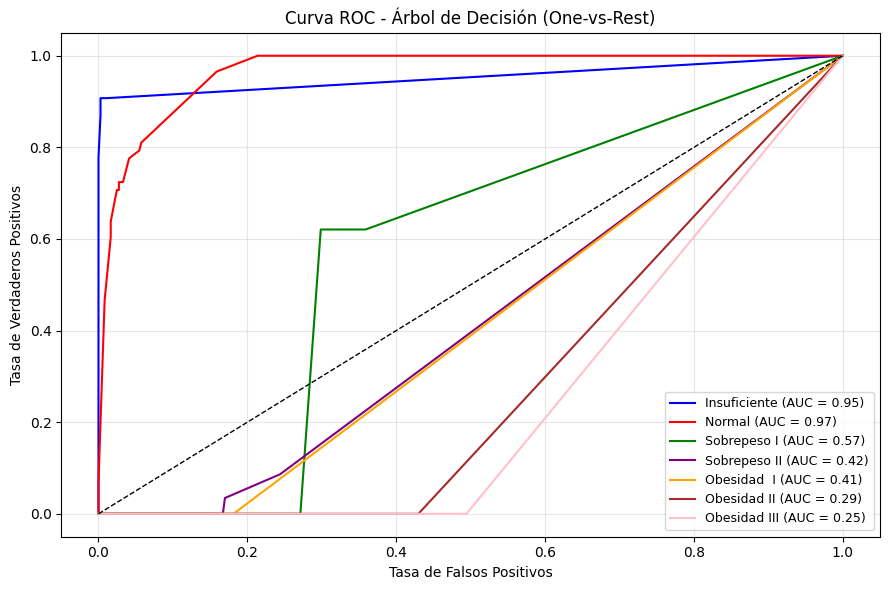

In [72]:
# binarizamos etiquetas (One-vs-Rest)
y_test_bin = label_binarize(y_test_c, classes=order)

# probabilidades
y_proba_arbol = arbol_clf.predict_proba(X_test_c)

colores_roc = ['blue', 'red', 'green', 'purple', 'orange', 'brown', 'pink']

plt.figure(figsize=(9, 6))
for i, (clase, color) in enumerate(zip(order, colores_roc)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba_arbol[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=1.5, label=f'{clase} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC - Árbol de Decisión (One-vs-Rest)')
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

El modelo muestra una capacidad de discriminación muy buena para las clases Insuficiente (AUC = 0.95) y Normal (AUC = 0.97). Las curvas se aproximan significativamente a la esquina superior izquierda, lo que indica que el algoritmo identifica con gran éxito a estos individuos manteniendo una cantidad de falsos positivos muy baja.

Por otro lado, bemos una gran degradación del rendimiento conforme aumenta el grado de obesidad. Las clases Obesidad II (AUC = 0.29) y Obesidad III (AUC = 0.25) presentan valores de AUC muy inferiores a 0.50 (la línea diagonal de azar). Esto indica que el modelo no solo no distingue estas clases, sino que sus predicciones son peores que el azar.

<a id="2-6-importancia-de-variables-arbol-de-decision-clasificador"></a>

### 2.6 Importancia de variables – Árbol de Decisión Clasificador

Igual que en la regresión, usamos `feature_importances_` para ver qué variables usa más el árbol al clasificar.

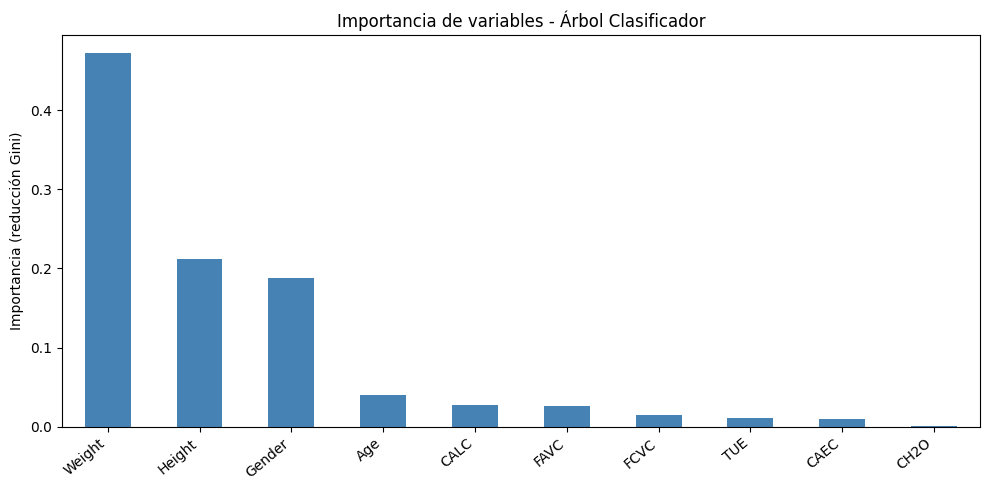

Top 5:
Weight    0.471486
Height    0.211714
Gender    0.187841
Age       0.040328
CALC      0.027316
dtype: float64


In [73]:
importancias_clf = pd.Series(arbol_clf.feature_importances_, index=features_clf)
importancias_clf = importancias_clf.sort_values(ascending=False)

plt.figure(figsize=(10, 5))
importancias_clf.head(10).plot(kind='bar', color='steelblue')
plt.title('Importancia de variables - Árbol Clasificador')
plt.ylabel('Importancia (reducción Gini)')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

print("Top 5:")
print(importancias_clf.head(5))

Vemos que el peso (`Weight`) es la variable con mayor poder de discriminación (0.47) para determinar el nivel de obesidad. Además, destaca también la relevancia de la altura (`Height`) y el género (`Gender`).

Por el contrario, variables relacionadas con el comportamiento diario, como el consumo de agua (CH2O), el tiempo frente a pantallas (TUE) o el consumo de alcohol (CALC), tienen una importancia muy pequeña en la clasificación final. Esto nos dice que, para este modelo, los factores físicos y biológicos predominan sobre los hábitos en el momento de categorizar el estado de obesidad de un individuo.

<a id="2-7-visualizacion-del-arbol-de-decision-clasificador"></a>

### 2.7 Visualización del árbol de decisión clasificador

Visualizamos los primeros 3 niveles para ver cómo divide el espacio el árbol.  

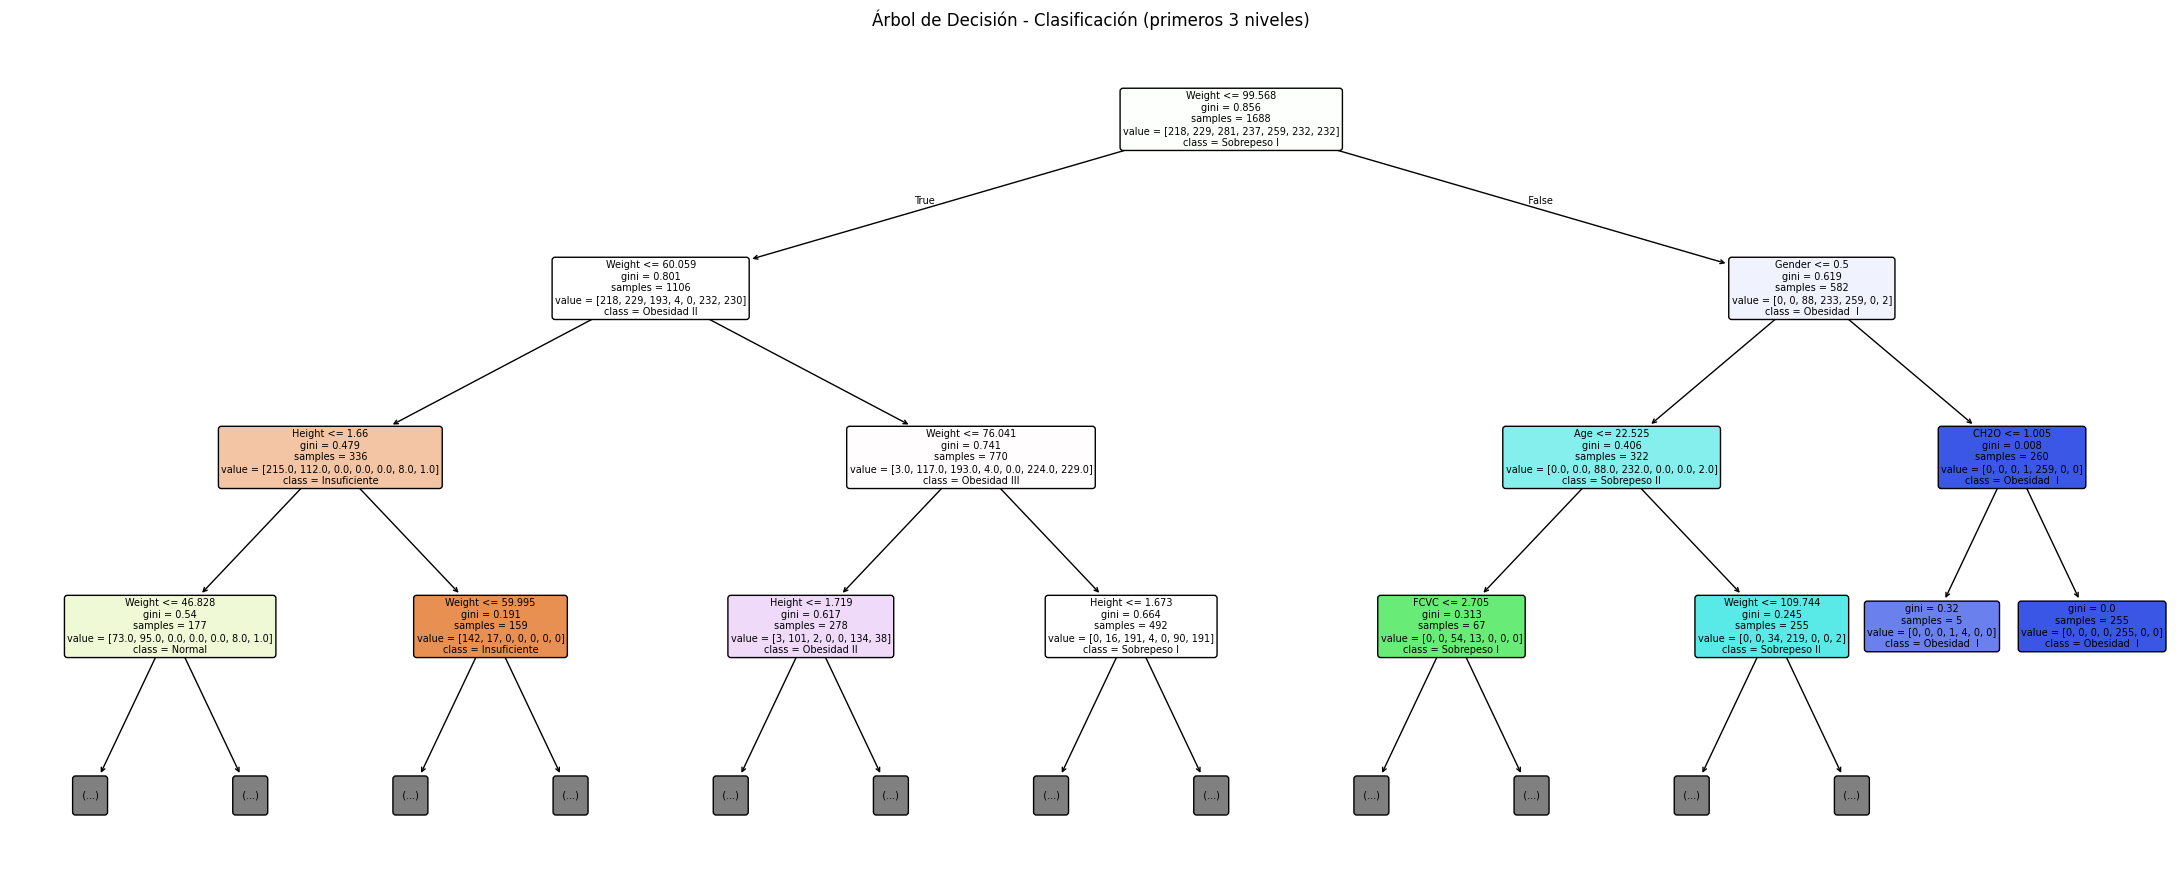

In [74]:
plt.figure(figsize=(22, 9))
plot_tree(arbol_clf,
          feature_names=features_clf,
          class_names=order,
          filled=True,
          rounded=True,
          max_depth=3,
          fontsize=7,
          impurity=True)
plt.title('Árbol de Decisión - Clasificación (primeros 3 niveles)')
plt.tight_layout()
plt.show()

Vemos que el nodo raíz utiliza el peso (`Weight`) con un umbral de 99.56 kg como el principal discriminador. En los siguientes niveles, el modelo separa las categorías integrando la altura (`Height`) y el género (`Gender`), demostrando que la estructura biológica es la causa rpincipal de la clasificación, más que los hábitos.

<a id="2-8-profundidad-del-arbol-vs-accuracy"></a>

### 2.8 Profundidad del árbol vs accuracy

Igual que con la regresión, vemos cómo evoluciona el accuracy en train y test para elegir bien el `max_depth`.

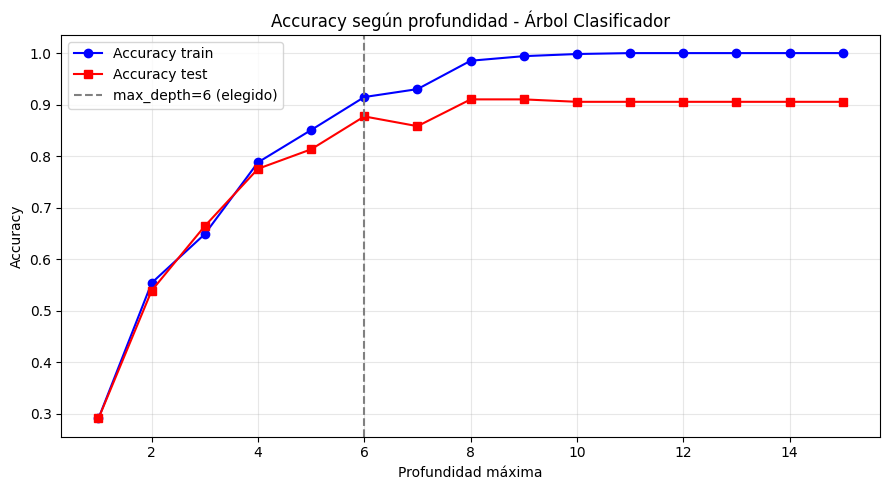

In [75]:
depths = list(range(1, 16))
acc_train_list = []
acc_test_list = []

for d in depths:
    m = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=42)
    m.fit(X_train_c, y_train_c)
    acc_train_list.append(accuracy_score(y_train_c, m.predict(X_train_c)))
    acc_test_list.append(accuracy_score(y_test_c, m.predict(X_test_c)))

plt.figure(figsize=(9, 5))
plt.plot(depths, acc_train_list, 'o-', label='Accuracy train', color='blue')
plt.plot(depths, acc_test_list, 's-', label='Accuracy test', color='red')
plt.axvline(x=6, color='gray', linestyle='--', label='max_depth=6 (elegido)')
plt.xlabel('Profundidad máxima')
plt.ylabel('Accuracy')
plt.title('Accuracy según profundidad - Árbol Clasificador')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Determinamos que una profundidad máxima de 6 es el punto óptimo de operación. En este nivel, el modelo maximiza su precisión en el conjunto de test (alcanzando un Accuracy de casi 90%) antes de que la curva de entrenamiento vaya al sobreajuste. Esta elección nos garantiza que el algoritmo no "memorice" casos particulares, sino que aprenda reglas generales aplicables a nuevos individuos.

<a id="2-9-efecto-del-escalado"></a>

### 2.9 Efecto del escalado

Los árboles de decisión no son sensibles al escalado porque no usan distancias, solo puntos de corte. Lo comprobamos entrenando el mismo árbol pero con datos escalados.

In [76]:
arbol_scaled = DecisionTreeClassifier(criterion='gini', max_depth=6, random_state=42)
arbol_scaled.fit(X_train_scaled, y_train_c)
acc_scaled = accuracy_score(y_test_c, arbol_scaled.predict(X_test_scaled))

print(f"Árbol sin escalar: {acc_arbol:.3f}")
print(f"Árbol escalado: {acc_scaled:.3f}")

Árbol sin escalar: 0.861
Árbol escalado: 0.877


El resultado es casi igual. Esto confirma que los árboles son invariantes al escalado.

### 2.10 Interpretación de los resultados de clasificación

**Accuracy:**

- El **árbol de decisión** (depth=6) consigue una accuracy de 0.861, lo cual es muy bueno para un problema de 7 clases.
- **KNN (k=7)** consigue un 0.797, un poco más pequeño. La diferencia se explica porque KNN trabaja en un espacio de 19 dimensiones donde la "maldición de la dimensionalidad" hace que las distancias pierdan sentido. El árbol en cambio divide el espacio de forma jerárquica y adapta cada split a las variables más relevantes.

**Matriz de confusión:**

- Los errores se concentran entre clases adyacentes en la escala (por ejemplo, `Sobrepeso I` con `Sobrepeso II`), lo cual es lógico porque las fronteras entre clases contiguas son difusas.
- Las clases extremas (`Insuficiente`, `Obesidad III`) se clasifican mejor porque sus perfiles son más distintivos.

**Curva ROC:**

- Los valores de AUC superiores a 0.95 en las categorías base demuestran una excelente capacidad para separar las clases del resto de la muestra. No obstante, se observa una ligera degradación en la discriminación de los grados más altos de obesidad, donde las características físicas tienden a solaparse.

**Estructura del árbol:**
- Los primeros nodos usan `Weight` y `Height` para separar las clases, lo cual recrean implícitamente los umbrales del IMC. A partir del nivel 3 ya aparecen variables de hábitos como `family_history_with_overweight`.

<a id="3-resumen"></a>

## 3. Resumen

| Tarea | Modelo | Métrica principal | Valor |
|-------|--------|------------------|-------|
| Regresión | Árbol de Decisión (depth=5) | R² | 0.70 |
| Regresión | Regresión Lineal | R² | 0.55 |
| Regresión | Ridge | R² | 0.55 |
| Clasificación | Árbol de Decisión (depth=6) | Accuracy | 0.86 |
| Clasificación | KNN (k=7) | Accuracy | 0.80 |

En conclusión, en ambas tareas el árbol de decisión supera a los modelos lineales, lo que indica que las relaciones entre hábitos y obesidad son no lineales e interactivas.

<a id="parte-2-ensembles-y-clustering"></a>

## **PARTE 2: ENSEMBLES Y CLUSTERING**

Para la segunda parte de la práctica es necesario realizar de forma obligatoria dos tareas: una de ensembles y otra de clustering. 
Para ello, se deberá buscar uno o varios datasets por internet que cumplan los requisitos especificados en el siguiente párrafo, así como plantear los objetivos que se pretenden realizar, las visualizaciones a mostrar y las conclusiones extraídas.

Requisitos de la segunda parte:

* El dataset o datasets de ensembles podrá ser el mismo que el utilizado para clasificación.
* El dataset o datasets de clustering debe de tener un mínimo de 3 dimensiones.
* En el caso del ensemble, la clasificación a realizar será de igual forma que en la parte anterior del tipo multilabel (debe de tener un mínimo de 3 clases a predecir).

<a id="1-clustering"></a>

## 1. CLUSTERING

Vamos a comenzar haciendo un clustering sobre las variables de hábitos de los individuos, para ver si emergen perfiles de estilo de vida independientemente de la etiqueta de obesidad, y compararlos después con `NObeyesdad`.

<a id="1-1-kmeans-y-pca"></a>

### 1.1 KMEANS y PCA

Vamos a comenzar aplicando el algoritmo de las K medias para las variables de hábitos: 
* family_history_with_overweight
* FAVC
* FCVC
* NCP
* CAEC
* SMOKE
* CH20
* SCC
* FAF
* TUE
* CALC 

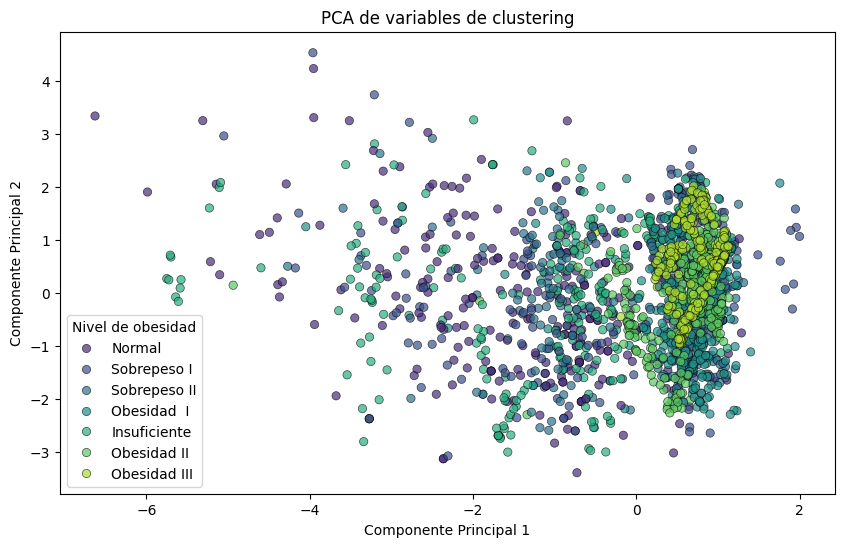

In [77]:
clustering_vars = [
    "family_history_with_overweight",  # binaria 0/1
    "FAVC",                            # binaria 0/1
    "FCVC",                            # escala 1-3
    "NCP",                             # escala 1-4
    "CAEC",                            # ordinal 0-3
    "SMOKE",                           # binaria 0/1
    "CH2O",                            # escala 1-3
    "SCC",                             # binaria 0/1
    "FAF",                             # escala 0-3
    "TUE",                             # escala 0-2
    "CALC",                            # ordinal 0-3
]

Y = obesity['NObeyesdad']

# Primero hacemos un PCA para reducir dimensionalidad y visualizar mejor las relaciones entre individuos antes de clusterizar.

X_scaled = StandardScaler().fit_transform(obesity[clustering_vars].copy())
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled) 
plt.figure(figsize=(10,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=Y, palette='viridis', alpha=0.7, edgecolor='k')
plt.title('PCA de variables de clustering')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(title='Nivel de obesidad')
plt.show()


Como podemos ver, antes de aplicar el algoritmo de las K medias, no se pueden desagrupar muy bien los clusters pero sí que se pueden sacar algunas conclusiones. 

Parece como que a mayor nivel de obesidad más a la derecha de la primera componente principal se sitúan los individuos y viceversa.

Veámos a partir de qué variables se crea cada componente.

In [78]:
# Veámos de qué está fromada cada componente principal para entender qué variables están más relacionadas con cada eje.
pca_components = pd.DataFrame(pca.components_, columns=clustering_vars, index=['PC1', 'PC2'])
print(pca_components)   

     family_history_with_overweight      FAVC      FCVC       NCP      CAEC  \
PC1                        0.500193  0.505808 -0.066002 -0.019039 -0.441485   
PC2                        0.184649 -0.101338  0.309077  0.440145 -0.040404   

        SMOKE      CH2O       SCC       FAF       TUE      CALC  
PC1 -0.106291  0.198947 -0.442386 -0.185167  0.034219  0.110890  
PC2  0.070765  0.585347  0.139927  0.519844  0.031986  0.162073  


La primera está conformada sobre todo por las variables family_history y FAVC en positivo y CAEC y SCC en negativo.

Mientras que la segunda está conformada sobre todo por las variables NCP, CH20. FAF  FCVC.

Con esta información podemos discurrir las siguientes hipótesis:

1. La PC1 está relacionada con un "eje de riesgo estructurado" porque define un perfil de predisposición + una dieta calórica sin control. consciente, pero con estructura de comidas fija (porque no hay picoteo entre horas).
    * Así, los individuos con un PC1 alto son aquellos con el estilo tradicional de riesgo de obesidad: carga genética que comen fuerte, no pican entre hroas pero tampoco cuentan las calorías.
    * Los individuos con un PC1 bajo no tienen antecedentes familiares y presentan una dieta menos calórica, aunque sí que picotean y también cuentan las calorías. Por tanto, es un perfil más consciente pero picoteador.

2. La PC2 parece más bien un eje de actividad/ calidad de la alimentación, con FAF, CH20 y FCVC. Sería un eje que separa:
    * Extremo activo y consciente: pratica deporte, come verduras en sus 3-4 comidas y bebe mucha agua.
    * Extremo sedentario: poca actividad, pocas comidas/verduras y poca agua.

Veámos cuánta de la varianza son capaces de explicar estas 2 componentes principales:

In [79]:
# Varianza explicada por cada componente
explained_variance = pca.explained_variance_ratio_
print(f"Varianza explicada por PC1: {explained_variance[0]:.2f}")
print(f"Varianza explicada por PC2: {explained_variance[1]:.2f}")   

# Varianza explicada conjuntamente por ambos componentes
total_explained_variance = explained_variance.sum()
print(f"Varianza explicada por PC1 y PC2 conjuntamente: {total_explained_variance:.2f}")    


Varianza explicada por PC1: 0.14
Varianza explicada por PC2: 0.12
Varianza explicada por PC1 y PC2 conjuntamente: 0.26


Por tanto, como vemos, 2 componentes no es suficiente para explicar ni la mitad de la varianza. Vamos a aplicar la regla del codo para ver con cuántas componentes principales lograríamos explicar al menos el 80% de la varianza.

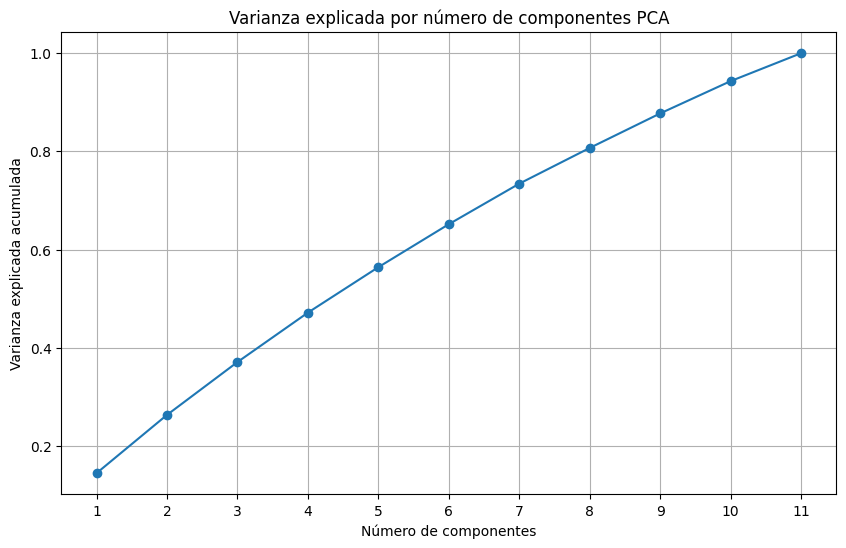

In [80]:
x = np.arange(1, 12)
varianza_explicada = []
for i in range(1, 12):
    pca = PCA(n_components=i)
    X_pca = pca.fit_transform(X_scaled) 
    # Varianza total explicada por los primeros i componentes
    explained_variance = pca.explained_variance_ratio_.sum()
    varianza_explicada.append(explained_variance)

# Graficamos:
plt.figure(figsize=(10,6))
plt.plot(x, varianza_explicada, marker='o')
plt.title('Varianza explicada por número de componentes PCA')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.xticks(x)
plt.grid()
plt.show()

Con 8 componentes ya explicaríamos un poco más del 80% de la varianza.

No obstante, 8 componentes es bastante. Es por esto que el PCA no es el método más eficiente para clusterizar usando nuestro dataset.

Ahora sí vamos con el algoritmo de las K medias que usaremos también para comparar con estos resultados previos.

In [81]:
X = obesity[clustering_vars].values

# De nuevo es importante escalar antes de aplicar el algoritmo
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Queremos 7 clusters. uno por cada clase de obesidad.
k = 7
kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

# Comparamos con la etiqueta real
ari = adjusted_rand_score(obesity["NObeyesdad"], clusters)
print(f"ARI vs NObeyesdad: {ari:.3f}")


ARI vs NObeyesdad: 0.184


El ARI o Adjusted Rand Index mide el parecido entre 2 particiones del mismo conjunto, en este caso los clusters del KMeans y los clusters reales de NObeyesidad.

Es una medida que toma valores hasta el 1, siendo el 0 coincidencias al nivel del azar, por lo que un ARI = 0.184 es un poco débil. Los clusters no recuperan las 7 clases de obesidad, aunque capturan algo de estructura relacionada.

Veámos ahora cómo se proyectan los clusters del algoritmo haciendo de nuevo un PCA.


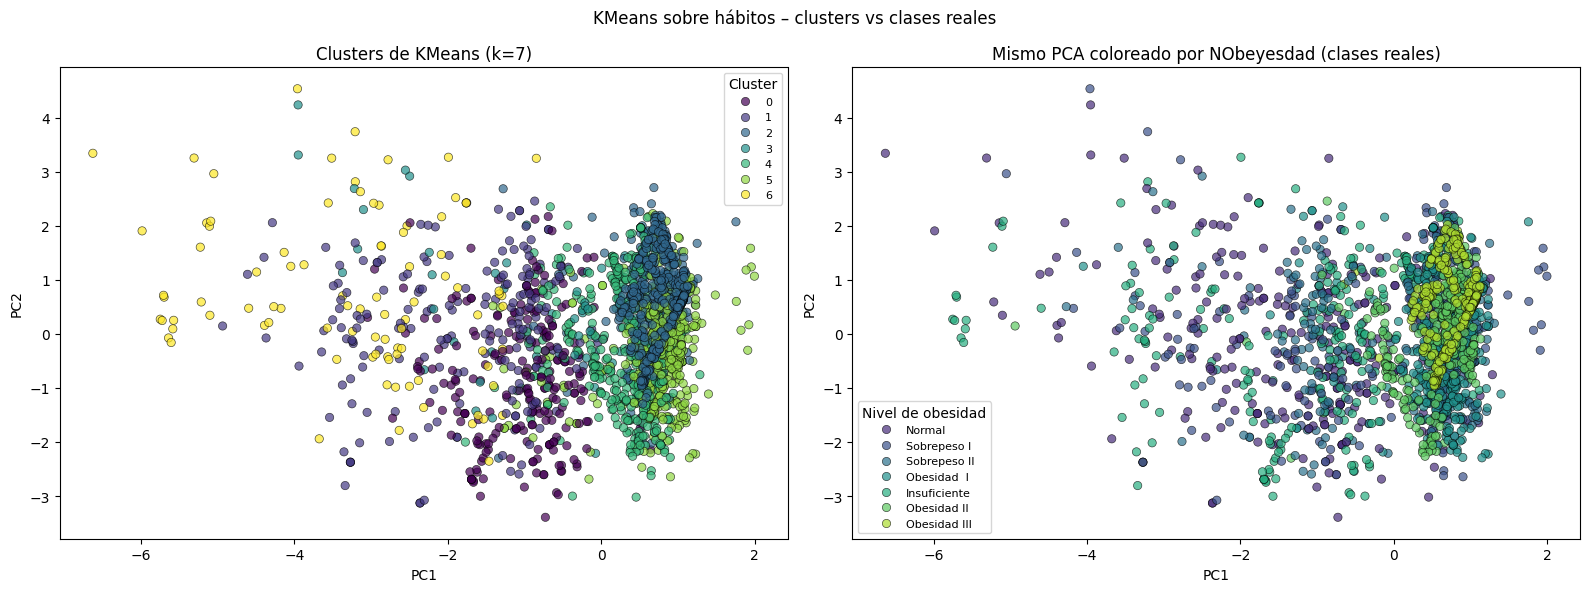

Varianza explicada PC1+PC2: 26.29%


In [82]:
# Proyección PCA: izquierda los clusters del algoritmo, derecha las clases reales de NObeyesdad
pca_km = PCA(n_components=2)
X_pca_km = pca_km.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x=X_pca_km[:, 0], y=X_pca_km[:, 1],
                hue=clusters, palette='viridis',
                alpha=0.7, edgecolor='k', ax=axes[0])
axes[0].set_title('Clusters de KMeans (k=7)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(title='Cluster', loc='best', fontsize=8)

sns.scatterplot(x=X_pca_km[:, 0], y=X_pca_km[:, 1],
                hue=obesity['NObeyesdad'], palette='viridis',
                alpha=0.7, edgecolor='k', ax=axes[1])
axes[1].set_title('Mismo PCA coloreado por NObeyesdad (clases reales)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(title='Nivel de obesidad', loc='best', fontsize=8)

plt.suptitle('KMeans sobre hábitos – clusters vs clases reales')
plt.tight_layout()
plt.show()

print(f"Varianza explicada PC1+PC2: {pca_km.explained_variance_ratio_.sum()*100:.2f}%")


El PCA con 2 componentes tras aplicar las K medias explica un 26.3% de la varianza total, que tampoco es mucho más con respecto a la varianza total que explica el PCA sin nada previo, de 26%.

Esto nos indica que los hábitos por sí solos no reproducen la etiqueta de IMC; es decir, el KMeans sobre hábitos descubre perfiles de estilo de vida, pero no los niveles de obesidad como tal.

Veámos ahora si cambiaría el resultado si añadiéramos las variables para los métodos de transporte utilizados.


In [83]:
clustering_vars = [
    "family_history_with_overweight",  # binaria 0/1
    "FAVC",                            # binaria 0/1
    "FCVC",                            # escala 1-3
    "NCP",                             # escala 1-4
    "CAEC",                            # ordinal 0-3
    "SMOKE",                           # binaria 0/1
    "CH2O",                            # escala 1-3
    "SCC",                             # binaria 0/1
    "FAF",                             # escala 0-3
    "TUE",                             # escala 0-2
    "CALC",                            # ordinal 0-3
    # Añadimos los métodos de transporte (one-hot de MTRANS)
    "MTRANS_Automobile",
    "MTRANS_Bike",
    "MTRANS_Motorbike",
    "MTRANS_Public_Transportation",
    "MTRANS_Walking",
]

# Asegurarnos de que las columnas one-hot existen; si no, las creamos.
mtrans_cols = [c for c in clustering_vars if c.startswith('MTRANS_')]
if not all(c in obesity.columns for c in mtrans_cols):
    obesity = pd.get_dummies(obesity, columns=['MTRANS'], drop_first=False)

X = obesity[clustering_vars].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 7
kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

ari = adjusted_rand_score(obesity["NObeyesdad"], clusters)
print(f"ARI vs NObeyesdad (con MTRANS): {ari:.3f}")


ARI vs NObeyesdad (con MTRANS): 0.096


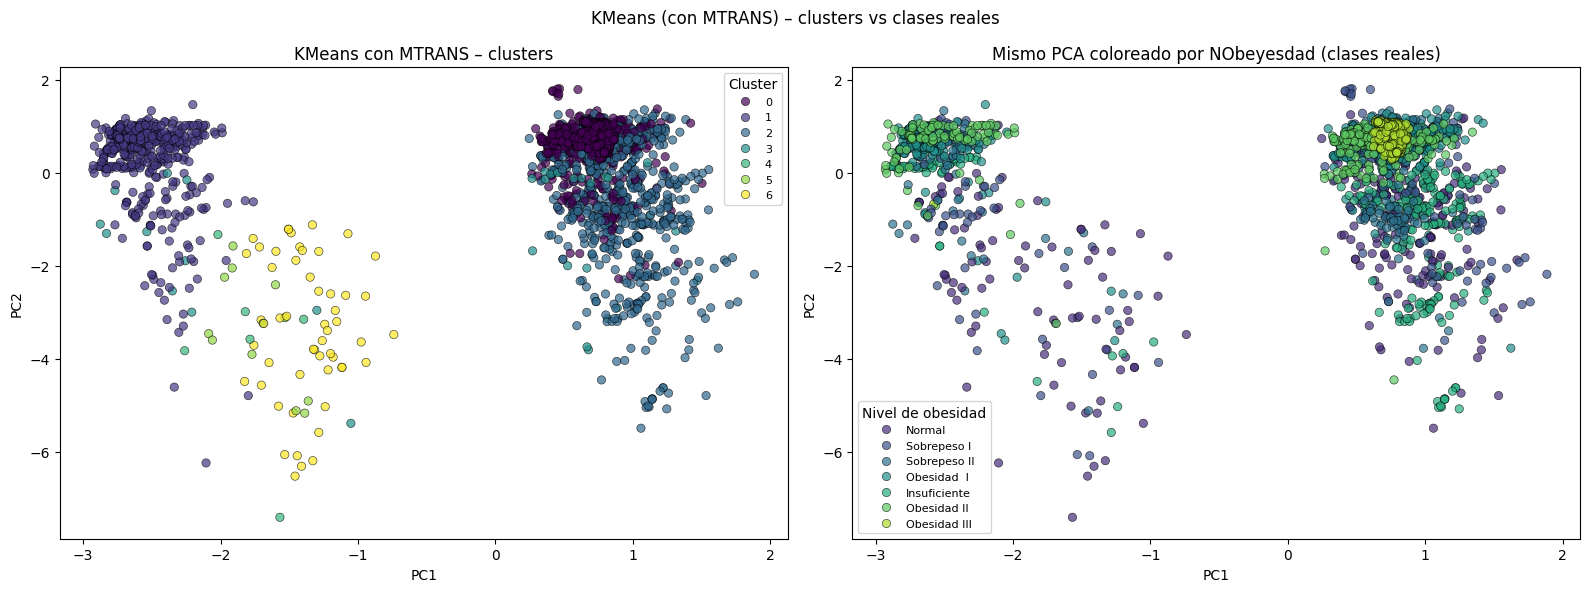

Varianza explicada PC1+PC2: 23.12%


In [84]:
# Proyección PCA: izquierda los clusters del algoritmo, derecha las clases reales de NObeyesdad
pca_km = PCA(n_components=2)
X_pca_km = pca_km.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x=X_pca_km[:, 0], y=X_pca_km[:, 1],
                hue=clusters, palette='viridis',
                alpha=0.7, edgecolor='k', ax=axes[0])
axes[0].set_title('KMeans con MTRANS – clusters')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(title='Cluster', loc='best', fontsize=8)

sns.scatterplot(x=X_pca_km[:, 0], y=X_pca_km[:, 1],
                hue=obesity['NObeyesdad'], palette='viridis',
                alpha=0.7, edgecolor='k', ax=axes[1])
axes[1].set_title('Mismo PCA coloreado por NObeyesdad (clases reales)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(title='Nivel de obesidad', loc='best', fontsize=8)

plt.suptitle('KMeans (con MTRANS) – clusters vs clases reales')
plt.tight_layout()
plt.show()

print(f"Varianza explicada PC1+PC2: {pca_km.explained_variance_ratio_.sum()*100:.2f}%")


Ahora ha empeorado tanto el ARI como el porcentaje de varianza explicada por las 2 primeras componentes principales del PCA aplicado a los clusters del algoritmo.

Lo que vamos a hacer a continuación es aplicar un último método de clustering visto en clase, el de las mixturas Gaussianas, que ha demostrado ser bastante útil cuando las nubes de puntos están muy revueltas y/o dispersas.


<a id="1-2-modelos-de-mixturas-gaussianas"></a>

### 1.2 Modelos de Mixturas Gaussianas


El modelo de mixturas Gaussianas asigna cada individuo a un cluster con una probabilidad, no un bloque duro como KMeans. En nuestro gráfico PCA se ve que las fronteras entre perfiles son difusas porque no hay huecos limpios, así que un modelo que admite pertenencia parcial puede que se ajuste mejor. Además, permite clusters elípticos y de distinta forma/tamaño, mientras que KMeans solo ve esferas.

No obstante, debemos mencionar que en nuestro caso, casi todas las variables son ordinales o binarias, y el Gaussian Mixture asume que cada componente es gaussiana continua, por lo que el modelo probabilístico no va a ser estrictamente correcto. Por eso debemos tener cuidado con las interpretaciones que hagamos del mismo.


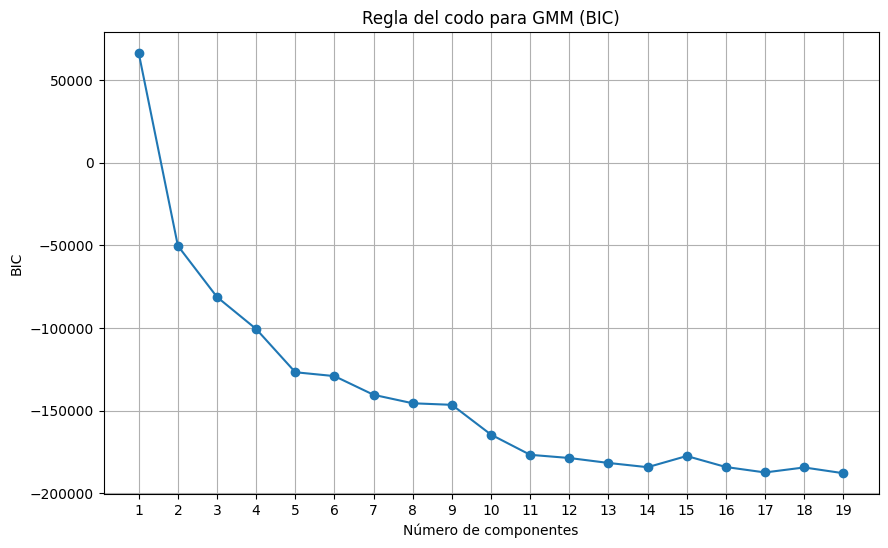

In [85]:

# Elegimos k de nuevo con la regla del codo (pero esta vez usando el BIC, no la varianza total explicada,
# por cambiar un poco de método).
Nc = range(1, 20)
bics = []
for k in Nc:
    gmm_tmp = GaussianMixture(n_components=k, covariance_type='full',
                              random_state=42, n_init=3)
    gmm_tmp.fit(X_scaled)
    bics.append(gmm_tmp.bic(X_scaled))

plt.figure(figsize=(10, 6))
plt.plot(list(Nc), bics, marker='o')
plt.title('Regla del codo para GMM (BIC)')
plt.xlabel('Número de componentes')
plt.ylabel('BIC')
plt.xticks(list(Nc))
plt.grid()
plt.show()


Los 2 codos más marcados se dan para k = 4 y k = 7. No obstante, escogemos k = 7 para poder compararlo con los métodos anteriores.


ARI GMM vs NObeyesdad: 0.141


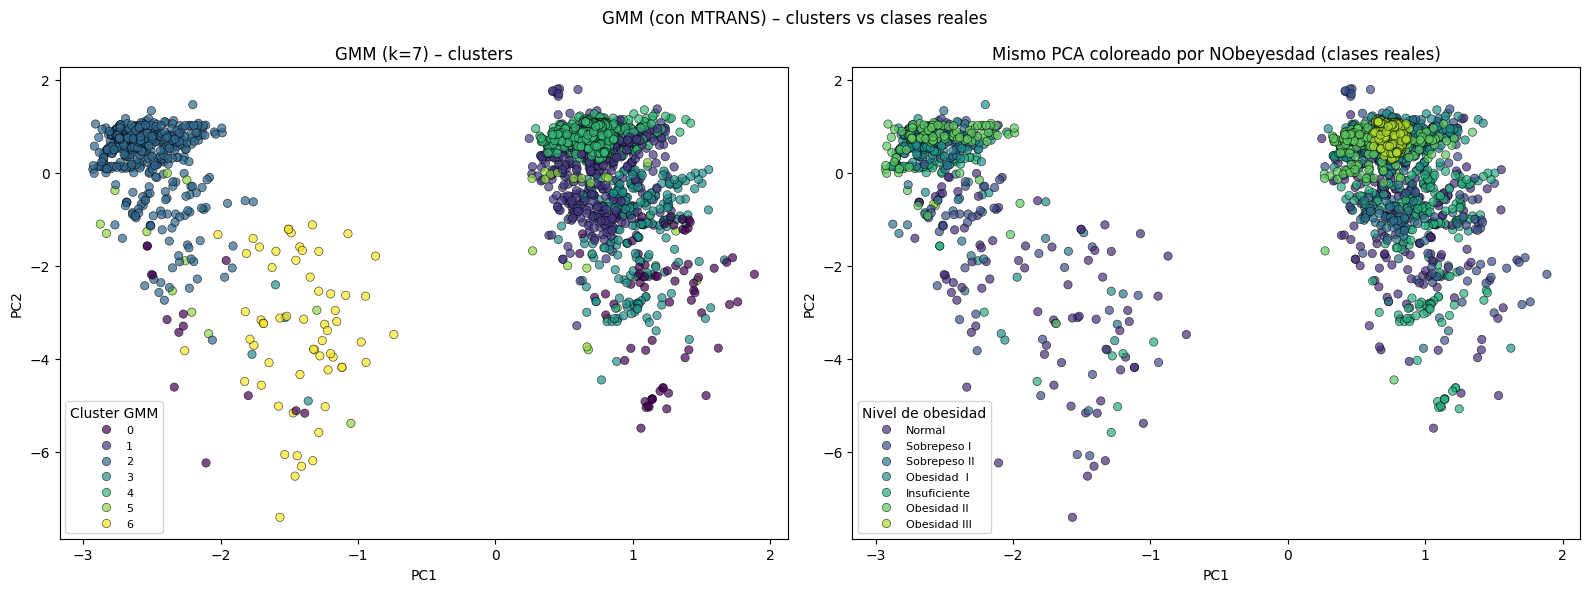

Varianza explicada PC1+PC2: 23.12%


In [86]:
# GMM con k=7 para comparar directamente con KMeans
gmm = GaussianMixture(
    n_components=7,
    covariance_type='full',
    random_state=42,
    n_init=10
)
clusters_gmm = gmm.fit_predict(X_scaled)

ari_gmm = adjusted_rand_score(obesity["NObeyesdad"], clusters_gmm)
print(f"ARI GMM vs NObeyesdad: {ari_gmm:.3f}")

pca_km = PCA(n_components=2)
X_pca_km = pca_km.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x=X_pca_km[:, 0], y=X_pca_km[:, 1],
                hue=clusters_gmm, palette='viridis',
                alpha=0.7, edgecolor='k', ax=axes[0])
axes[0].set_title('GMM (k=7) – clusters')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(title='Cluster GMM', loc='best', fontsize=8)

sns.scatterplot(x=X_pca_km[:, 0], y=X_pca_km[:, 1],
                hue=obesity['NObeyesdad'], palette='viridis',
                alpha=0.7, edgecolor='k', ax=axes[1])
axes[1].set_title('Mismo PCA coloreado por NObeyesdad (clases reales)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(title='Nivel de obesidad', loc='best', fontsize=8)

plt.suptitle('GMM (con MTRANS) – clusters vs clases reales')
plt.tight_layout()
plt.show()

print(f"Varianza explicada PC1+PC2: {pca_km.explained_variance_ratio_.sum()*100:.2f}%")


Con k = 7 obtenemos un ARI mejor que con el algoritmo de las K medias y todas las variables de estilo de vida y el PCA con 2 componentes aplicado a los clusters del algoritmo explica un 23.12% de la varianza total.

Además, el GMM nos revela una estructura bimodal en los hábitos que el KMeans no podía poner tan en evidencia, y es que hay dos grupos poblacionales claramente separados en el eje de abscisas.


In [87]:
# Printeamos la importancia de cada variable en el PCA para entender qué variables están más relacionadas con cada componente.
pca_components = pd.DataFrame(pca_km.components_, columns=clustering_vars, index=['PC1', 'PC2'])
print(pca_components.T.round(3))


                                  PC1    PC2
family_history_with_overweight -0.105  0.428
FAVC                           -0.010  0.501
FCVC                            0.063 -0.055
NCP                            -0.072 -0.045
CAEC                            0.035 -0.399
SMOKE                          -0.020 -0.098
CH2O                            0.034  0.122
SCC                             0.052 -0.390
FAF                            -0.031 -0.234
TUE                             0.191  0.005
CALC                            0.024  0.110
MTRANS_Automobile              -0.665  0.073
MTRANS_Bike                    -0.052 -0.124
MTRANS_Motorbike               -0.062 -0.146
MTRANS_Public_Transportation    0.689  0.093
MTRANS_Walking                 -0.112 -0.330


La PC1 es casi enteramente un eje de transporte: coche vs. transporte público, y todas las demás componentes son prácticamente ruido. Esto explica el hueco entre las 2 nubes, porque las variables de MTRANS son binarias así que solo pueden tomar 2 valores.

Veámos qué pasaría si quitáramos las variables MTRANS.


ARI GMM (sin MTRANS) vs NObeyesdad: 0.122


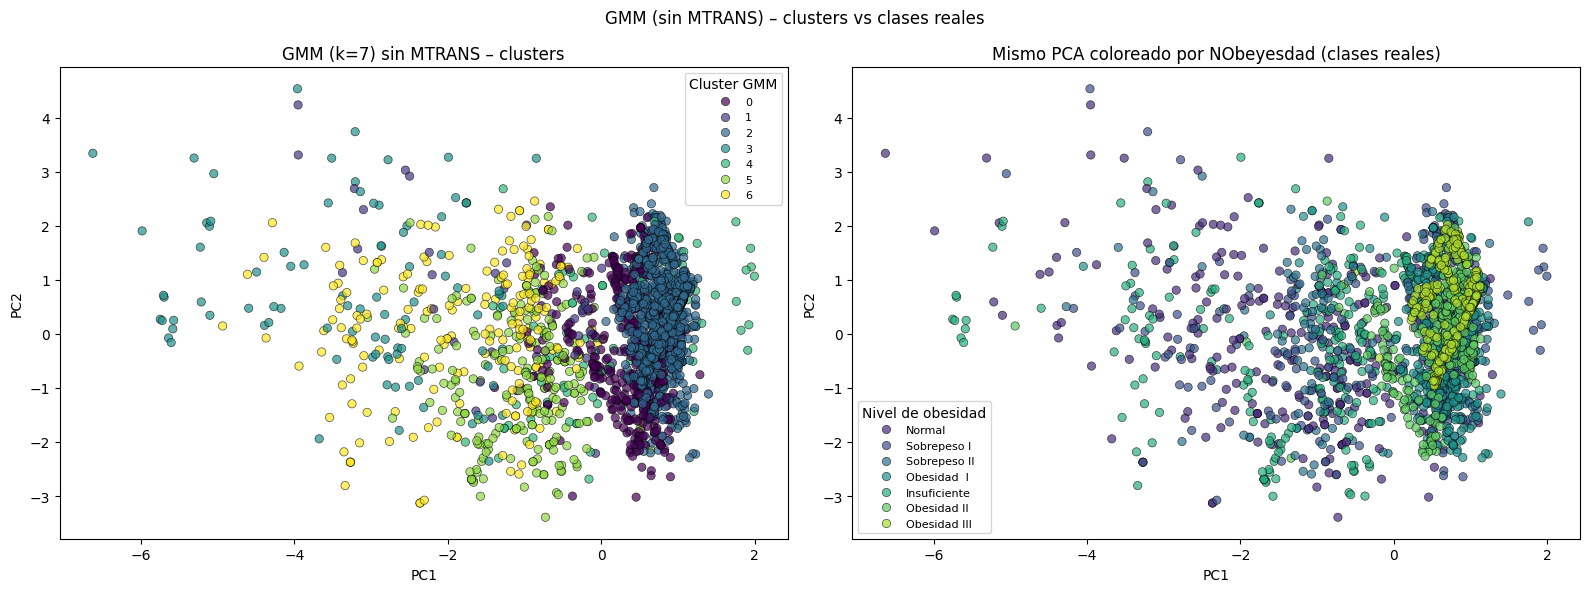

Varianza explicada PC1+PC2: 26.29%


In [88]:
clustering_vars = [
    "family_history_with_overweight",
    "FAVC",
    "FCVC",
    "NCP",
    "CAEC",
    "SMOKE",
    "CH2O",
    "SCC",
    "FAF",
    "TUE",
    "CALC",
]

X = obesity[clustering_vars].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

gmm = GaussianMixture(
    n_components=7,
    covariance_type='full',
    random_state=42,
    n_init=10
)
clusters_gmm = gmm.fit_predict(X_scaled)

ari_gmm = adjusted_rand_score(obesity["NObeyesdad"], clusters_gmm)
print(f"ARI GMM (sin MTRANS) vs NObeyesdad: {ari_gmm:.3f}")

pca_km = PCA(n_components=2)
X_pca_km = pca_km.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(x=X_pca_km[:, 0], y=X_pca_km[:, 1],
                hue=clusters_gmm, palette='viridis',
                alpha=0.7, edgecolor='k', ax=axes[0])
axes[0].set_title('GMM (k=7) sin MTRANS – clusters')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend(title='Cluster GMM', loc='best', fontsize=8)

sns.scatterplot(x=X_pca_km[:, 0], y=X_pca_km[:, 1],
                hue=obesity['NObeyesdad'], palette='viridis',
                alpha=0.7, edgecolor='k', ax=axes[1])
axes[1].set_title('Mismo PCA coloreado por NObeyesdad (clases reales)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(title='Nivel de obesidad', loc='best', fontsize=8)

plt.suptitle('GMM (sin MTRANS) – clusters vs clases reales')
plt.tight_layout()
plt.show()

print(f"Varianza explicada PC1+PC2: {pca_km.explained_variance_ratio_.sum()*100:.2f}%")


Ahora obviamente ya no está la separación en el eje x. La varianza explicada total es un poco mejor y también un poco mejor que la del PCA aplicado al KMeans sin estas variables. El ARI también es ligeramente más alto que antes pero no tan alto como el del KMeans con 7 clusters y sin las variables de transporte.


<a id="1-3-conclusiones-de-los-metodos-de-clustering"></a>

### 1.3 Conclusiones de los métodos de clustering.

Como breve conclusión tras el uso de distintos métodos de clustering podemos decir varias cosas:

1. Los hábitos por sí solos no recuperan los niveles de obesidad, pues ningún método superó un ARI de 0.184, aunque sí descubren perfiles de estilo de vida. Esto es coherente con los resultados que obtuvimos en la parte 1, pues allí eran las variables relacionadas con el IMC las que dominaban la importancia en la clasificación.

2. Añadir variables no siempre suma, pues en nuestro caso es el método más simple (KMeans sin MTRANS) el que más se alineó con la variable. El PCA demostró que añadir las variables MTRANS hizo que estas se quedaran con la primera componente principal dejando a las demás de estilo de vida y hábitos relegadas a la segunda componente principal. Esto es una buena lección pues variables nominales one-hot con alta varianza pueden monopolizar componentes sin aportar señales en la tarea que nos concierne.


<a id="2-ensembles"></a>

## 2. ENSEMBLES

En la Parte 1 vimos que los árboles de decisión superaban a los modelos lineales (regresión lineal, Ridge) en regresión y a KNN en clasificación. Esto sugería que las relaciones entre hábitos y nivel de obesidad son no lineales e interactivas, lo que hace de los árboles un buen punto de partida.

Ahora vamos a comprobar si agregar muchos árboles mediante técnicas de ensemble mejora aún más los resultados, que es la hipótesis natural tras la Parte 1.

Cubrimos los dos paradigmas clásicos de ensembles:

- **Bagging (Random Forest):** muchos árboles entrenados en paralelo sobre muestras bootstrap, agregados por votación o promedio. Reduce la varianza.
- **Boosting (Gradient Boosting):** árboles entrenados secuencialmente, cada uno corrigiendo el error del anterior. Reduce el sesgo.

Y al final añadimos un **Voting Classifier** que combina varios modelos heterogéneos (árbol, KNN y Random Forest), para cerrar la narrativa con la Parte 1.

<a id="2-1-random-forest"></a>

### 2.1 Random Forest

Random Forest entrena muchos árboles sobre muestras bootstrap de los datos, y en cada split considera solo un subconjunto aleatorio de variables. Esto reduce la correlación entre árboles y, al promediar sus predicciones, reduce drásticamente la varianza del árbol individual.

In [89]:

# --- Regresión ---
rf_reg = RandomForestRegressor(
    n_estimators=300, max_depth=None, min_samples_leaf=2,
    random_state=42, n_jobs=-1, oob_score=True
)
rf_reg.fit(X_train, y_train)
y_pred_rf_reg = rf_reg.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf_reg))
mae_rf  = mean_absolute_error(y_test, y_pred_rf_reg)
r2_rf   = r2_score(y_test, y_pred_rf_reg)

print("Random Forest Regressor")
print(f"    RMSE      : {rmse_rf:.2f} kg")
print(f"    MAE       : {mae_rf:.2f} kg")
print(f"    R²        : {r2_rf:.3f}")
print(f"    OOB score : {rf_reg.oob_score_:.3f}")


Random Forest Regressor
    RMSE      : 8.78 kg
    MAE       : 5.40 kg
    R²        : 0.891
    OOB score : 0.888


In [90]:
# --- Clasificación ---
rf_clf = RandomForestClassifier(
    n_estimators=300, max_depth=None, min_samples_leaf=2,
    random_state=42, n_jobs=-1, oob_score=True
)
rf_clf.fit(X_train_c, y_train_c)
y_pred_rf_clf = rf_clf.predict(X_test_c)

acc_rf = accuracy_score(y_test_c, y_pred_rf_clf)
print(f"Random Forest Classifier")
print(f"    Accuracy  : {acc_rf:.3f}")
print(f"    OOB score : {rf_clf.oob_score_:.3f}")
print()
print(classification_report(y_test_c, y_pred_rf_clf, target_names=order))


Random Forest Classifier
    Accuracy  : 0.955
    OOB score : 0.950

              precision    recall  f1-score   support

Insuficiente       1.00      0.94      0.97        54
      Normal       0.80      0.98      0.88        58
 Sobrepeso I       0.96      0.97      0.96        70
Sobrepeso II       1.00      0.98      0.99        60
 Obesidad  I       1.00      0.98      0.99        65
 Obesidad II       0.98      0.86      0.92        58
Obesidad III       0.98      0.95      0.96        58

    accuracy                           0.96       423
   macro avg       0.96      0.95      0.96       423
weighted avg       0.96      0.96      0.96       423



El **OOB score** (Out-Of-Bag) es la accuracy estimada sobre las muestras que cada árbol no vio durante su entrenamiento (el ~37% que el bootstrap deja fuera). Es una estimación gratuita de generalización (no requiere validación cruzada) y debería estar próxima al accuracy de test.

Random Forest **mejora claramente** sobre el árbol individual de la Parte 1 tanto en regresión como en clasificación, gracias a la reducción de varianza.

<a id="2-2-gradient-boosting"></a>

### 2.2 Gradient Boosting

Mientras Random Forest entrena árboles **independientes en paralelo** (bagging), Gradient Boosting los entrena **secuencialmente**: cada árbol nuevo se ajusta a los **residuos** del anterior, corrigiendo gradualmente los errores. Es la técnica de ensembles más usada en competiciones y suele dar accuracy ligeramente superior a costa de mayor sensibilidad a hiperparámetros.

In [91]:
# --- Regresión ---
gb_reg = GradientBoostingRegressor(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    random_state=42
)
gb_reg.fit(X_train, y_train)
y_pred_gb_reg = gb_reg.predict(X_test)

rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb_reg))
mae_gb  = mean_absolute_error(y_test, y_pred_gb_reg)
r2_gb   = r2_score(y_test, y_pred_gb_reg)

print("Gradient Boosting Regressor")
print(f"    RMSE : {rmse_gb:.2f} kg")
print(f"    MAE  : {mae_gb:.2f} kg")
print(f"    R²   : {r2_gb:.3f}")


Gradient Boosting Regressor
    RMSE : 10.77 kg
    MAE  : 8.12 kg
    R²   : 0.836


In [92]:
# --- Clasificación ---
gb_clf = GradientBoostingClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.05,
    random_state=42
)
gb_clf.fit(X_train_c, y_train_c)
y_pred_gb_clf = gb_clf.predict(X_test_c)

acc_gb = accuracy_score(y_test_c, y_pred_gb_clf)
print(f"Gradient Boosting Classifier")
print(f"    Accuracy : {acc_gb:.3f}")
print()
print(classification_report(y_test_c, y_pred_gb_clf, target_names=order))


Gradient Boosting Classifier
    Accuracy : 0.955

              precision    recall  f1-score   support

Insuficiente       1.00      0.91      0.95        54
      Normal       0.84      1.00      0.91        58
 Sobrepeso I       0.97      0.96      0.96        70
Sobrepeso II       0.97      0.97      0.97        60
 Obesidad  I       1.00      0.98      0.99        65
 Obesidad II       0.95      0.90      0.92        58
Obesidad III       0.98      0.97      0.97        58

    accuracy                           0.96       423
   macro avg       0.96      0.95      0.95       423
weighted avg       0.96      0.96      0.96       423



<a id="2-3-voting-classifier"></a>

### 2.3 Voting Classifier

El Voting Classifier combina **modelos heterogéneos** (árbol, KNN, Random Forest) por votación. Cada modelo emite su predicción y se agrega:

- **Hard voting:** voto mayoritario.
- **Soft voting:** promedio de probabilidades de pertenencia a cada clase. Suele funcionar mejor si los modelos están calibrados.

Es una forma natural de cerrar el círculo con la Parte 1: combinamos los modelos que ya entrenamos individualmente para ver si su unión supera al mejor de ellos por separado.

In [93]:

# KNN necesita datos escalados, así que lo envolvemos en un Pipeline con StandardScaler
voting = VotingClassifier(
    estimators=[
        ('dt',  DecisionTreeClassifier(criterion='gini', max_depth=6,
                                       min_samples_leaf=5, random_state=42)),
        ('knn', Pipeline([('scaler', StandardScaler()),
                          ('knn', KNeighborsClassifier(n_neighbors=7))])),
        ('rf',  RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                       random_state=42, n_jobs=-1)),
    ],
    voting='soft'
)
voting.fit(X_train_c, y_train_c)
y_pred_voting = voting.predict(X_test_c)

acc_voting = accuracy_score(y_test_c, y_pred_voting)
print(f"Voting Classifier (DT + KNN + RF, soft voting)")
print(f"    Accuracy : {acc_voting:.3f}")
print()
print(classification_report(y_test_c, y_pred_voting, target_names=order))


Voting Classifier (DT + KNN + RF, soft voting)
    Accuracy : 0.920

              precision    recall  f1-score   support

Insuficiente       1.00      0.91      0.95        54
      Normal       0.80      0.83      0.81        58
 Sobrepeso I       0.89      0.97      0.93        70
Sobrepeso II       0.95      0.98      0.97        60
 Obesidad  I       1.00      0.98      0.99        65
 Obesidad II       0.83      0.86      0.85        58
Obesidad III       0.98      0.88      0.93        58

    accuracy                           0.92       423
   macro avg       0.92      0.92      0.92       423
weighted avg       0.92      0.92      0.92       423



<a id="2-4-comparativa-final"></a>

### 2.4 Comparativa final

Reunimos todos los modelos de la Parte 1 y la Parte 2 para ver el progreso completo.

In [94]:
# Tabla comparativa de regresión
resultados_reg_full = pd.DataFrame({
    'Modelo': ['Árbol de Decisión', 'Regresión Lineal', 'Ridge',
               'Random Forest', 'Gradient Boosting'],
    'RMSE (kg)': [rmse_arbol, rmse_lr, rmse_ridge, rmse_rf, rmse_gb],
    'MAE (kg)' : [mae_arbol,  mae_lr,  mae_ridge,  mae_rf,  mae_gb],
    'R²'       : [r2_arbol,   r2_lr,   r2_ridge,   r2_rf,   r2_gb],
})
print("=== REGRESIÓN ===")
print(resultados_reg_full.to_string(index=False))
print()

# Tabla comparativa de clasificación
resultados_clf_full = pd.DataFrame({
    'Modelo'  : ['Árbol de Decisión', 'KNN (k=7)',
                 'Random Forest', 'Gradient Boosting', 'Voting (DT+KNN+RF)'],
    'Accuracy': [acc_arbol, acc_knn, acc_rf, acc_gb, acc_voting],
})
print("=== CLASIFICACIÓN ===")
print(resultados_clf_full.to_string(index=False))


=== REGRESIÓN ===
           Modelo  RMSE (kg)  MAE (kg)       R²
Árbol de Decisión  14.524713 10.356705 0.700803
 Regresión Lineal  17.786286 14.282497 0.551344
            Ridge  17.754310 14.193838 0.552956
    Random Forest   8.784039  5.396086 0.890571
Gradient Boosting  10.766057  8.117189 0.835617

=== CLASIFICACIÓN ===
            Modelo  Accuracy
 Árbol de Decisión  0.860520
         KNN (k=7)  0.796690
     Random Forest  0.955083
 Gradient Boosting  0.955083
Voting (DT+KNN+RF)  0.919622


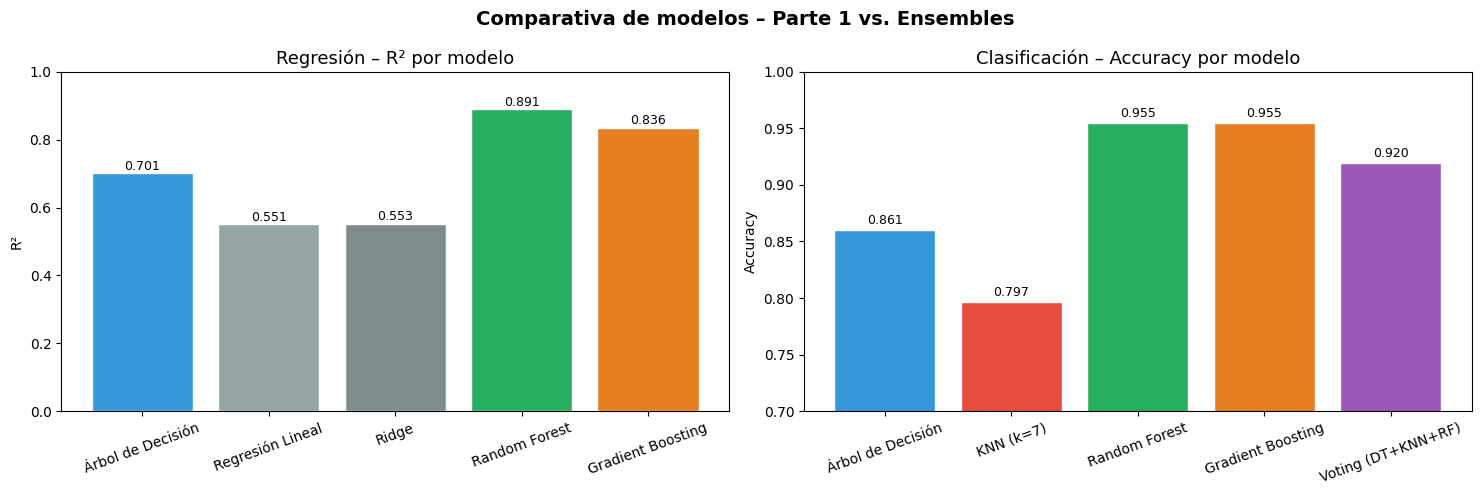

In [95]:
# Visualización comparativa
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Regresión: barras de R2
colors_reg = ['#3498db', '#95a5a6', '#7f8c8d', '#27ae60', '#e67e22']
axes[0].bar(resultados_reg_full['Modelo'], resultados_reg_full['R²'],
            color=colors_reg, edgecolor='white')
axes[0].set_title('Regresión – R² por modelo', fontsize=13)
axes[0].set_ylabel('R²')
axes[0].set_ylim(0, 1)
for i, v in enumerate(resultados_reg_full['R²']):
    axes[0].text(i, v + 0.01, f'{v:.3f}', ha='center', fontsize=9)
axes[0].tick_params(axis='x', rotation=20)

# Clasificación: barras de accuracy
colors_clf = ['#3498db', '#e74c3c', '#27ae60', '#e67e22', '#9b59b6']
axes[1].bar(resultados_clf_full['Modelo'], resultados_clf_full['Accuracy'],
            color=colors_clf, edgecolor='white')
axes[1].set_title('Clasificación – Accuracy por modelo', fontsize=13)
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0.7, 1.0)
for i, v in enumerate(resultados_clf_full['Accuracy']):
    axes[1].text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=9)
axes[1].tick_params(axis='x', rotation=20)

plt.suptitle('Comparativa de modelos – Parte 1 vs. Ensembles',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


Por último, vamos a comentar cómo es la importancia de las variables para el Random Forest frente al árbol individual, que es bastante interesante para estudiar cómo se producen las predicciones.

Random Forest reparte la importancia entre muchos árboles, lo que suele dar una visión más estable y equilibrada entre variables correlacionadas que el árbol individual. Comparamos ambas para clasificación.

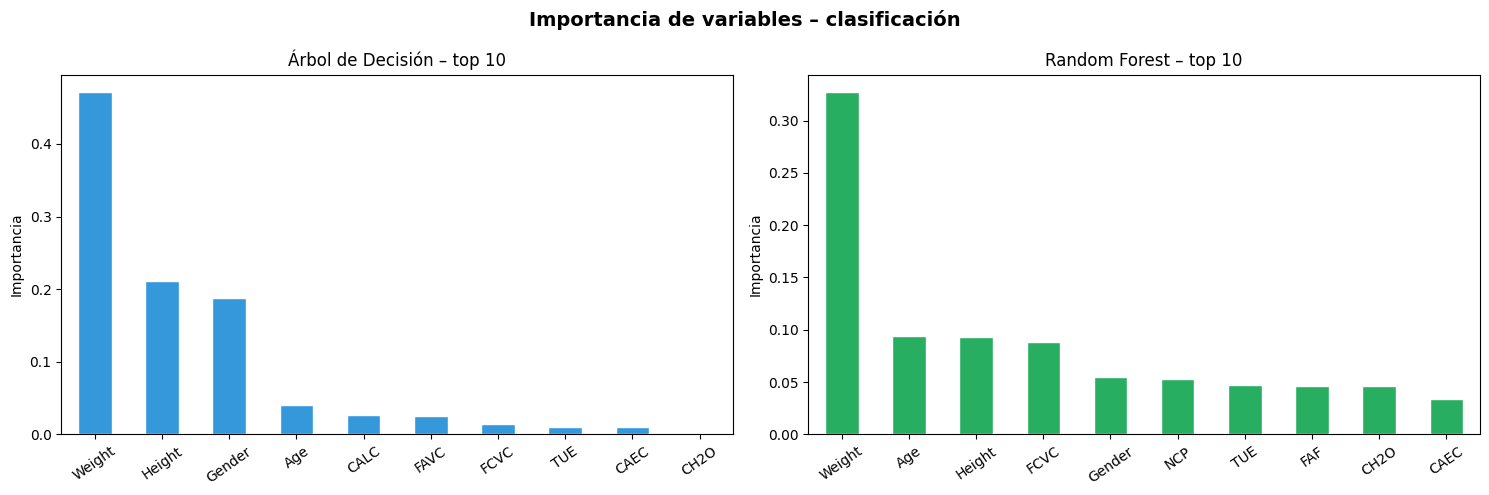

Top 5 árbol individual : ['Weight', 'Height', 'Gender', 'Age', 'CALC']
Top 5 Random Forest    : ['Weight', 'Age', 'Height', 'FCVC', 'Gender']


In [96]:
importancias_rf = pd.Series(rf_clf.feature_importances_, index=features_clf).sort_values(ascending=False)
importancias_dt = pd.Series(arbol_clf.feature_importances_, index=features_clf).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

importancias_dt.head(10).plot(kind='bar', ax=axes[0], color='#3498db', edgecolor='white')
axes[0].set_title('Árbol de Decisión – top 10', fontsize=12)
axes[0].set_ylabel('Importancia')
axes[0].tick_params(axis='x', rotation=35)

importancias_rf.head(10).plot(kind='bar', ax=axes[1], color='#27ae60', edgecolor='white')
axes[1].set_title('Random Forest – top 10', fontsize=12)
axes[1].set_ylabel('Importancia')
axes[1].tick_params(axis='x', rotation=35)

plt.suptitle('Importancia de variables – clasificación', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Top 5 árbol individual :", importancias_dt.head(5).index.tolist())
print("Top 5 Random Forest    :", importancias_rf.head(5).index.tolist())


Por tanto, son bastante parecidas. Obviamente la más importante para clasificar es el peso, pero el bosque es mñas inteligente que el árbol porque escoge la edad en lugar de la altura que está correlacionada spor motivos obvios con el peso.

No obstante, las tres variables dominantes (peso, altura, edad/género) coinciden, lo que confirma que ambos modelos explotan la misma señal central. Otra diferencia interesante está en el quinto puesto pues el árbol elige CALC (alcohol) mientras que Random Forest elige FCVC (verduras). RF tiende a repartir la importancia entre variables correlacionadas (FCVC y otras de hábitos alimentarios), mientras que el árbol único concentra el peso en una sola.

<a id="2-6-conclusiones-de-los-ensembles"></a>

### 2.6 Conclusiones de los ensembles

1. Verificación de la hipótesis de la Parte 1:

    En la Parte 1 anticipábamos que los ensembles deberían mejorar al árbol individual al reducir su varianza. **Los resultados lo confirman con creces**:

    - Clasificación: del 0.86 del árbol al 0.957 de Random Forest (+10 puntos).
    - Regresión: del $R^2$ = 0.70 del árbol al $R^2$ = 0.89 de Random Forest (RMSE baja de 14.5 kg a 8.8 kg, casi a la mitad).

2. El hallazgo más interesante: bagging gana a boosting:

    Contra la intuición habitual (Gradient Boosting suele dominar en competiciones), aquí **Random Forest supera a Gradient Boosting**:

    - En clasificación empatan (0.957 vs 0.955).
    - En regresión RF gana claramente ($R^2$ 0.89 vs 0.84).

    La interpretación es que el problema es de varianza, no de sesgo pues las clases ya están razonablemente separadas por `Weight` y `Height`. Bagging, que ataca la varianza promediando árboles independientes, es la respuesta natural. Boosting, que reduce el sesgo corrigiendo errores secuencialmente, no aporta tanto cuando el problema no es de sesgo.

3. El Voting Classifier empeora respecto a sus ensembles individuales:

    Accuracy del Voting (0.920) por debajo de RF (0.957) y GB (0.955). Esto se debe a que estamos promediando un modelo fuerte (RF) con dos más débiles (DT 0.86, KNN 0.80) sin ponderar. Cuando los modelos están en rangos de calidad muy distintos, la votación no sale tan bien como cabría esperar.

4. Techo de rendimiento:

    Ambos ensembles fuertes (RF, GB) se sitúan en torno al 95-96% de accuracy. El 4-5% de error residual se concentra en confusiones entre clases adyacentes (Sobrepeso II↔Obesidad I, Obesidad I↔II), que vimos claramente en el PCA que se solapaban, lo que es coherente con la propia naturaleza del IMC.




<a id="3-resumen-2"></a>

## 3. Resumen

Finalmente, como conclusión final del trabajo podríamos decir que la relación entre hábitos y nivel de obesidad es fundamentalmente no lineal e interactiva.

La no-linealidad la descubrimos en la parte 1 y medianet los ensembles pudimos obtener modelos robustos, como nuestra combinación ganadora de no-linealidad + reducción de varianza.

Por otro lado, mediante el clustering descubrimos que los hábitos por sí solos no son capaces de recuperar el IMC, pero que combinados con otras variables como el peso y la altura sí que pueden predecir el nivel de obesidad con un nivel de acierto de hasta el 96%. Es decir, que aunque son una señal secundaria, se convierten en una señal útil combinados con variables antropométricas.
